# 1.07. Графическое тестирование

**План занятия**

1. Напоминание: FWER, FDR, классические поправки и почему их не хватает для иерархии гипотез.
2. Формальный аппарат: вершины, веса, матрица переходов и алгоритм.
3. Связь с замкнутой процедурой тестирования и контроль FWER.
4. Разбор примеров: Бонферрони, Холм, фиксированная последовательность, гейткипинг, ε-рёбра.
5. Расширения для контроля k-FWER и FDP: дополненный и обобщённый подходы.
6. Методологические расширения: запутанные графы, групповые последовательные дизайны, параметрические тесты.
7. Кейсы из клинических исследований и симуляция A/B-теста.
8. Практические рекомендации.

### Библиотеки и реализация алгоритма

In [1]:
import itertools
from fractions import Fraction

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from ipywidgets import Dropdown, FloatSlider, IntSlider, interact
from matplotlib.patches import FancyArrowPatch
from statsmodels.stats.multitest import multipletests

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'

BLUE, RED, GREEN, GRAY = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F'


def update_graph(weights: np.ndarray, G: np.ndarray, j: int) -> tuple:
    """Удаляет вершину j: передаёт её вес по рёбрам и пересчитывает матрицу переходов."""
    m = len(weights)
    new_weights = weights + weights[j] * G[j]
    new_weights[j] = 0.0

    new_G = np.zeros((m, m))
    for l in range(m):
        for k in range(m):
            if l == k or j in (l, k):
                continue
            denominator = 1.0 - G[l, j] * G[j, l]
            if denominator > 1e-12:  # если вершины передают друг другу всё, ребро обнуляется
                new_G[l, k] = (G[l, k] + G[l, j] * G[j, k]) / denominator
    return new_weights, new_G


def run_steps(weights: np.ndarray, G: np.ndarray, pvalues: np.ndarray, level: float, active: list, max_rejections: int = None) -> tuple:
    """Шаги алгоритма на уровне level, пока есть что отвергать, но не более max_rejections отвержений."""
    weights, G = np.array(weights, dtype=float), np.array(G, dtype=float)
    active, rejected, history = list(active), [], []

    while active and (max_rejections is None or len(rejected) < max_rejections):
        candidates = [i for i in active if weights[i] > 0]
        if not candidates:
            break
        j = min(candidates, key=lambda i: pvalues[i] / weights[i])
        rejects = pvalues[j] <= weights[j] * level
        history.append({'active': list(active), 'weights': weights.copy(), 'G': G.copy(), 'tested': j, 'rejected': rejects})
        if not rejects:
            break
        weights, G = update_graph(weights, G, j)
        active.remove(j)
        rejected.append(j)

    return rejected, weights, G, active, history


def graph_test(weights: np.ndarray, G: np.ndarray, pvalues: np.ndarray, alpha: float = 0.05) -> list:
    """Графическая процедура: возвращает отвергнутые гипотезы в порядке отвержения."""
    return run_steps(weights, G, pvalues, alpha, range(len(weights)))[0]


def subset_weights(weights: np.ndarray, G: np.ndarray, keep: list) -> np.ndarray:
    """Считает веса w_i(I) для пересечения гипотез из keep, удаляя все остальные вершины."""
    weights, G = np.array(weights, dtype=float), np.array(G, dtype=float)
    for j in set(range(len(weights))) - set(keep):
        weights, G = update_graph(weights, G, j)
    return weights


def closed_test(weights: np.ndarray, G: np.ndarray, pvalues: np.ndarray, alpha: float = 0.05) -> list:
    """Полная замкнутая процедура: перебирает все 2^m - 1 пересечений."""
    m = len(weights)
    rejected_sets = {}
    for size in range(1, m + 1):
        for subset in itertools.combinations(range(m), size):
            local = subset_weights(weights, G, subset)
            rejected_sets[subset] = any(pvalues[i] <= local[i] * alpha for i in subset)
    return [i for i in range(m) if all(result for subset, result in rejected_sets.items() if i in subset)]


def augmented_test(weights: np.ndarray, G: np.ndarray, pvalues: np.ndarray, alpha: float = 0.05,
                   k: int = None, gamma: float = None, delta: float = 1.0) -> list:
    """Дополненная процедура: контроль k-FWER (k) или FDP (gamma), после FWER-этапа идём с уровнем delta."""
    rejected, weights, G, active, _ = run_steps(weights, G, pvalues, alpha, range(len(weights)))
    if gamma is not None:
        extra = int(np.floor(gamma * len(rejected) / (1 - gamma) + 1e-12))  # наибольшее D: D / (D + |R|) <= gamma
    else:
        extra = k - 1
    return rejected + run_steps(weights, G, pvalues, delta, active, max_rejections=extra)[0]


def generalised_kfwer(weights: np.ndarray, G: np.ndarray, pvalues: np.ndarray, alpha: float = 0.05, k: int = 1) -> list:
    """Обобщённая процедура для k-FWER (алгоритм 3 из Robertson et al., 2020)."""
    all_hypotheses = set(range(len(weights)))
    current = subset_weights(weights, G, all_hypotheses)
    R = {i for i in all_hypotheses if pvalues[i] <= current[i] * k * alpha}
    I = all_hypotheses - R
    if len(R) < k or not I:
        return sorted(R)

    while I:
        thresholds = {i: 1.0 for i in I}
        for J in itertools.combinations(sorted(R), k - 1):
            local = subset_weights(weights, G, I | set(J))
            thresholds = {i: min(thresholds[i], local[i]) for i in I}
        new = {i for i in I if pvalues[i] <= thresholds[i] * k * alpha}
        if not new:
            break
        I -= new
        R |= new
    return sorted(R)


def generalised_fdp(weights: np.ndarray, G: np.ndarray, pvalues: np.ndarray, alpha: float = 0.05, gamma: float = 0.1) -> list:
    """Обобщённая процедура для FDP (алгоритм 6 из Robertson et al., 2020)."""
    k = 1
    while True:
        rejected = generalised_kfwer(weights, G, pvalues, alpha, k)
        if len(rejected) < k / gamma - 1:
            return rejected
        k += 1


def format_share(value: float, symbol: str = '') -> str:
    """Записывает долю как дробь: 1/2 или 2α/3 для весов вершин."""
    if value == 0:
        return '0'
    if value < 1e-3:
        return 'ε'
    if 1 - 1e-3 < value < 1:
        return '≈1' if not symbol else f'≈{symbol}'
    frac = Fraction(float(value)).limit_denominator(100)
    top = '' if symbol and frac.numerator == 1 else str(frac.numerator)
    text = f'{top}{symbol}'
    return text if frac.denominator == 1 else f'{text}/{frac.denominator}'


def circle_layout(m: int) -> np.ndarray:
    """Размещает m вершин на окружности."""
    angles = np.pi / 2 - 2 * np.pi * np.arange(m) / m
    return np.column_stack([np.cos(angles), np.sin(angles)])


def draw_graph(ax, weights: np.ndarray, G: np.ndarray, labels: list, pos: np.ndarray = None, removed: tuple = (),
               tested: int = None, node_size: int = 1500, edge_labels: bool = True, font_size: int = 11) -> None:
    """Рисует граф гипотез: вес вершины указан под подписью, отвергнутые вершины показаны серым."""
    pos = circle_layout(len(weights)) if pos is None else np.asarray(pos, dtype=float)
    span = pos.max(axis=0) - pos.min(axis=0)
    span[span == 0] = 1

    for i, j in zip(*np.nonzero(G)):
        if i in removed or j in removed:
            continue
        rad = 0.18 if G[j, i] > 0 else 0.0
        ax.add_patch(FancyArrowPatch(pos[i], pos[j], connectionstyle=f'arc3,rad={rad}', arrowstyle='-|>', mutation_scale=15,
                                     shrinkA=node_size ** 0.5 / 1.75, shrinkB=node_size ** 0.5 / 1.75, color=GRAY, linewidth=1.5, zorder=1))
        if edge_labels:
            middle = (pos[i] + pos[j]) / 2
            direction = pos[j] - pos[i]
            normal = np.array([direction[1], -direction[0]])
            point = middle + normal * (rad * 0.55 + 0.04) + direction * 0.12
            ax.text(*point, format_share(G[i, j]), fontsize=font_size - 1, ha='center', va='center', zorder=2,
                    bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1})

    for i in range(len(weights)):
        done = i in removed
        ax.scatter(*pos[i], s=node_size, color='#E4E4E0' if done else BLUE, zorder=3, linewidths=3 if i == tested else 0,
                   edgecolors=RED if i == tested else 'none')
        text = labels[i] if done else f'{labels[i]}\n{format_share(weights[i], "α")}'
        ax.text(*pos[i], text, ha='center', va='center', fontsize=font_size, color=GRAY if done else 'white', zorder=4, fontweight='bold')

    ax.set_xlim(pos[:, 0].min() - 0.32 * span[0], pos[:, 0].max() + 0.32 * span[0])
    ax.set_ylim(pos[:, 1].min() - 0.32 * span[1], pos[:, 1].max() + 0.32 * span[1])
    ax.axis('off')


def show_procedure(weights: np.ndarray, G: np.ndarray, pvalues: np.ndarray, alpha: float = 0.05, labels: list = None,
                   pos: np.ndarray = None, panel_width: float = 4.6, panel_height: float = 3.9) -> pd.DataFrame:
    """Показывает все шаги алгоритма на графах и возвращает таблицу шагов."""
    weights, pvalues = np.array(weights, dtype=float), np.array(pvalues, dtype=float)
    labels = labels or [f'H{i + 1}' for i in range(len(weights))]
    rejected, final_weights, final_G, _, history = run_steps(weights, G, pvalues, alpha, range(len(weights)))

    panels = len(history) + 1
    fig, axes = plt.subplots(1, panels, figsize=(panel_width * panels, panel_height), squeeze=False)
    rows = []
    for number, (ax, step) in enumerate(zip(axes[0], history), 1):
        j = step['tested']
        threshold = step['weights'][j] * alpha
        removed = tuple(i for i in range(len(weights)) if i not in step['active'])
        draw_graph(ax, step['weights'], step['G'], labels, pos, removed, tested=j)
        verdict = 'отвергаем' if step['rejected'] else 'стоп'
        ax.set_title(f'Шаг {number}: {labels[j]}, p = {pvalues[j]:.4g}, порог {threshold:.4g}\n{verdict}', fontsize=11)
        rows.append({'Шаг': number, 'Проверяем': labels[j], 'p': pvalues[j], 'Порог': round(threshold, 5), 'Решение': verdict})
    removed = tuple(rejected)
    draw_graph(axes[0, -1], final_weights, final_G, labels, pos, removed)
    axes[0, -1].set_title('Итоговый граф\nотвергнуты: ' + (', '.join(labels[i] for i in rejected) or 'ничего'), fontsize=11)
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(rows).set_index('Шаг')

## Введение и напоминание базовых концепций

### Краткое напоминание: FWER, FDR и классические поправки

Прежде чем мы погрузимся в графический подход, давайте освежим в памяти тот фундамент, на котором всё строится. Вы уже знакомы с проблемой множественных сравнений и основными методами её решения, поэтому быстро пройдёмся по ключевым понятиям, но обязательно выделим те ограничения классических процедур, которые как раз и мотивировали создание графического подхода.

Итак, представим, что в рамках одного A/B-эксперимента или клинического исследования мы проверяем не одну, а сразу несколько нулевых гипотез: скажем, сравниваем несколько вариантов продукта по нескольким метрикам, или анализируем несколько конечных точек эффективности и безопасности. Классический пример из области, которую мы будем рассматривать, — клиническое исследование с двумя дозами препарата, тремя иерархически упорядоченными конечными точками, итого шесть элементарных гипотез. Или, что ближе вам, A/B-тест с контролем и тремя вариантами, где у каждого варианта есть основная метрика — выручка, и несколько guardrail-метрик, например, CTR и retention. Возникает вопрос: как нам принять решение по всему этому набору гипотез, сохраняя контроль над ошибками?

Проблема хорошо известна: если каждую из $m$ независимых нулевых гипотез проверять на привычном уровне значимости $\alpha$ (например, $0.05$), то вероятность совершить хотя бы одну ошибку I рода стремительно растёт. Формально:

$$
P(\text{хотя бы одна ошибка I рода}) = 1 - (1 - \alpha)^m\;.
$$

При $m = 10$ и $\alpha = 0.05$ эта вероятность уже около $0.40$, при $m = 20$ — порядка $0.64$. Иными словами, риск найти «значимое» различие просто в силу случайности становится очень большим. Поэтому нам нужны специальные метрики и процедуры, которые удерживают общую вероятность ложных выводов в заданных рамках.

Центральных метрики три.

1. **Групповая вероятность ошибки I рода**, Family-Wise Error Rate (FWER)

$$
FWER = P(V \ge 1)\;, \text{ где V — число ложноположительных результатов}
$$

Контроль FWER на уровне $\alpha$ означает, что при любом раскладе истинных и ложных гипотез вероятность допустить хотя бы одну такую ошибку не превышает $\alpha$. Этот критерий очень строг, и именно его требуют регуляторы для подтверждающих клинических испытаний, потому что главная цель — минимизировать риск пропуска на рынок неэффективного или небезопасного препарата.

2. **Доля ложных отклонений**, False Discovery Rate (FDR)

$$
FDR = \mathbb{E}\!\left[\frac{V}{\max(R,1)}\right]\;, \text{ где $R$ — общее число отвергнутых гипотез}
$$

Фактически FDR показывает, какую долю среди всех наших «находок» в среднем составляют ложные. Контроль на уровне, скажем, $0.05$ допускает, что в среднем 5% объявленных значимыми результатов будут ошибочными. Это более мягкий критерий, чем FWER, и он особенно популярен в задачах с тысячами гипотез, например, в геномике или нейровизуализации. В контексте A/B-тестов он тоже может применяться на разведочных стадиях.

3. **Обобщённая FWER**, $k$-FWER:

$$
k\text{-}FWER = P(V \ge k)\;.
$$

Она контролирует вероятность совершить $k$ или более ложных отклонений. При $k=1$ это обычный FWER. Увеличивая $k$, мы ослабляем контроль, но можем повысить мощность — это полезно, когда мы готовы мириться с одним-двумя лишними ложными сигналами ради обнаружения большего числа реальных эффектов.

Теперь вспомним три классические процедуры, которые вы уже знаете. Все они оперируют упорядоченными p-значениями: $p_{(1)} \le p_{(2)} \le \dots \le p_{(m)}$.

1. **Поправка Бонферрони** — отвергаем любую гипотезу $H_i$, для которой $p_i \le \alpha / m$. Она гарантирует $FWER \le \alpha$ без всяких предположений о зависимости p-значений, но платит за это чрезвычайной консервативностью.

2. **Процедура Холма**: мы идём от самого маленького p-значения к самому большому и сравниваем $p_{(i)}$ с порогом $\alpha/(m-i+1)$. Как только встречаем p-значение, которое больше своего порога, останавливаемся и отвергаем только предыдущие. Процедура Холма также контролирует FWER без каких-либо предположений о структуре зависимости и является более мощной, чем Бонферрони.

3. **Процедура Бенджамини–Хохберга**: ищется наибольшее $k$, для которого $p_{(k)} \le \frac{k}{m}\,\alpha$, и отвергаются все гипотезы с индексами от $1$ до $k$. Эта процедура гарантированно контролирует FDR только при независимости p-значений или при положительной регрессионной зависимости.

На первый взгляд, этого арсенала достаточно. Однако давайте задумаемся: все эти процедуры обращаются с гипотезами **симметрично** — каждая гипотеза изначально рассматривается как равноправная. Но в реальных задачах, особенно в клинических испытаниях и сложных A/B-тестах, гипотезы почти никогда не равноправны. У нас есть первичные конечные точки, которые обязательно должны быть значимы, чтобы исследование считалось успешным, и вторичные, которые мы тестируем только при условии успеха первичных. Есть иерархия важности, есть логические связи: например, мы не будем проверять безопасность дозировки, если не доказана её эффективность. Или в A/B-тестировании: сначала нужно убедиться, что новый интерфейс не уронил ключевую метрику продаж, а затем уже смотреть на вспомогательные метрики вовлечённости.

Ни Бонферрони, ни Холм, ни BH не позволяют естественным образом отразить такую логику. Они не знают, что уровень значимости, «сэкономленный» на отвержении какой-то вторичной гипотезы, должен быть передан обратно в первичное семейство, или что начальные права на проверку должны быть распределены неравномерно. В результате исследователи либо вынуждены применять кустарные, не вполне обоснованные схемы, либо теряют мощность там, где она критически важна.

Именно для преодоления этих ограничений Франк Бретц и его коллеги в 2009 году предложили **графический подход**. Ключевая идея — представить всё семейство гипотез в виде ориентированного взвешенного графа, где:

* вершины (узлы) — это элементарные нулевые гипотезы $H_i$;
* каждой вершине приписан начальный вес $\alpha_i$, причём сумма всех $\alpha_i$ не превышает общий уровень значимости $\alpha$;
* направленные рёбра от $H_i$ к $H_j$ имеют вес $g_{ij}$, который показывает, какая доля локального уровня $\alpha_i$ будет передана гипотезе $H_j$ после того, как $H_i$ отвергнута.

Таким образом, при отвержении гипотезы её уровень не пропадает, а **перераспределяется** по заданным правилам на оставшиеся, ещё не проверенные гипотезы. Это даёт возможность построить **последовательно отвергающую процедуру**, которая:

1. строго контролирует FWER на уровне $\alpha$;
2. учитывает приоритеты и логическую иерархию между гипотезами;
3. часто оказывается мощнее классических аналогов именно за счёт разумного «рециклинга» уровня значимости;
4. и, что немаловажно, представляет сложную стратегию тестирования в виде интуитивно понятной картинки, которую легко обсуждать с коллегами и регуляторами.

В последующих разделах мы формализуем этот подход, изучим его связь с замкнутой процедурой тестирования и увидим, как простые изменения в топологии графа превращают его из процедуры Бонферрони в процедуру Холма, затем в различные варианты гейткипинга и даже в процедуры, контролирующие $k$-FWER. А сейчас, прежде чем перейти к мотивации на конкретных примерах, зафиксируем главный тезис: **плоские процедуры не учитывают иерархию гипотез; графический подход решает именно эту проблему, сохраняя строгий контроль над ошибками**.

### Мотивация: от одного теста к сложному A/B-эксперименту

**Типичный A/B-тест: больше не «один вариант — одна метрика»**

Ещё несколько лет назад типовой онлайн-эксперимент выглядел так: у нас есть контрольная группа и один экспериментальный вариант, одна ключевая метрика успеха (скажем, конверсия в покупку) и несколько «охранных» метрик, которые мы проверяем на всякий случай. Сегодня же ландшафт гораздо сложнее. Рассмотрим несколько примеров, которые будем использовать на протяжении всей лекции.

**Пример 1. Три интерфейса корзины**
  
Предположим, продуктовая команда разработала три альтернативных интерфейса корзины: вариант A, вариант B и вариант C. Основная цель — увеличить средний чек. Одновременно нам критически важно не ухудшить пользовательский опыт: мы отслеживаем CTR на главную страницу, удержание (retention) через неделю и, возможно, время до первого заказа. Логика принятия решения такова:

1. Мы тестируем гипотезу о том, что вариант A превосходит контроль по revenue.  
2. Если это удалось доказать, только тогда мы проверяем, что A не ухудшает CTR, retention и время до заказа.  
3. Варианты B и C проверяются по revenue параллельно, на своих долях уровня значимости: провал варианта A не должен закрывать им дорогу.

Здесь мы имеем не плоское множество гипотез, а **двухуровневую иерархию**:
- **Первичный уровень:** три гипотезы о превосходстве по revenue для каждого варианта.
- **Вторичный уровень:** под каждой из этих гипотез висит семейство проверок на «не хуже» по вспомогательным метрикам.

**Пример 2. Клиническое исследование с несколькими дозами**

Классический учебный сценарий поздней фазы разработки препарата: две дозы нового лекарства сравниваются с плацебо по трём иерархически упорядоченным конечным точкам, например по частоте рецидивов, числу очагов на МРТ и прогрессированию инвалидизации. Итого шесть элементарных гипотез $H_{ij}$, где $i = 1$ означает высокую дозу, $i = 2$ низкую, а $j = 1, 2, 3$ номер конечной точки. Клиническая логика требует:

- если высокая доза не показала превосходства по первой, самой важной конечной точке, низкая доза всё равно проверяется, но только на своей доле уровня значимости;
- успех по первой точке «открывает ворота» к проверке второй точки, а затем третьей, в строгой последовательности.

**Пример 3. Многошаговый протокол «K из N»**

Исследование Pre-RELAX-AHF изучало препарат на многих конечных точках, связанных с острой сердечной недостаточностью, и один из критериев продолжения разработки заключался в эффекте на большинстве из них. На его основе Робертсон и соавторы рассматривают дизайн, где успех означает отвержение хотя бы 6 из 9 гипотез, и только после этого проверяются вторичные гипотезы. Логика здесь ещё сложнее: первичный успех определяется не одной гипотезой, а условием «хотя бы шесть из девяти».

**К чему приводит отсутствие учёта иерархии?**

Если мы воспользуемся классической процедурой Холма для всех гипотез одновременно, то каждый отдельный тест получит долю $\alpha$, пропорциональную общему числу гипотез, и порядок проверки будет диктоваться исключительно величиной p-значений. Это порождает две серьёзные проблемы:

1. **Неэффективное распределение $\alpha$.**

Предположим, в примере с вариантами интерфейса самый маленький p-value получился у варианта C по revenue, а следующий по величине — у варианта A по вспомогательной метрике. Процедура Холма потратит часть общего уровня $\alpha$ на проверку вспомогательной метрики варианта A, хотя вариант A ещё не доказал превосходства по основной метрике! Это противоречит бизнес-логике: мы не должны «тратить» статистический бюджет на проверку безопасности того, что не доказало эффективность.

2. **Риск преждевременной остановки.**

Представьте себе фиксированную последовательность тестов (fixed sequence test), где все гипотезы выстроены в одну цепочку $(H_{11} \to H_{21} \to H_{12} \to \dots \to H_{23})$. Если первая гипотеза $H_{11}$ (высокая доза vs плацебо по relapse rate) не отвергается на уровне $\alpha$, процедура немедленно останавливается, и все остальные гипотезы, даже с очень маленькими p-значениями, формально не могут быть отвергнуты. Исследование признаётся неуспешным полностью, хотя низкая доза, возможно, была эффективной. Жёсткая фиксация порядка тестирования, таким образом, приводит к неприемлемой потере мощности.

**Идея графического представления**

Графический подход преодолевает эти ограничения, предлагая мыслить о семействе гипотез как о **взвешенном ориентированном графе**, где рёбра несут в себе правила «наследования» уровня значимости. Вернёмся к примеру с двумя дозами и тремя endpoint'ами. Мы можем построить граф, в котором:

- Вершинам, соответствующим гипотезам эффективности первой (самой важной) конечной точки, присваиваются наибольшие начальные веса.
- Рёбра направлены от первичных гипотез к вторичным и от более важных endpoint'ов к менее важным.
- Веса рёбер определяют, как перераспределяется уровень $\alpha$ после отвержения той или иной гипотезы.

Например, мы можем договориться, что $\alpha$ распределяется поровну между двумя дозами, и внутри каждой дозы идёт фиксированная последовательность от первой конечной точки к третьей. В отличие от жёсткой фиксированной последовательности, провал высокой дозы не останавливает проверку низкой: у неё есть своя доля $\alpha/2$. А если высокая доза окажется успешной по всем трём endpoint'ам, освободившийся уровень будет передан для усиления тестов низкой дозы. Важно, что уровень передаётся только при **отвержении** гипотезы: неотвергнутая гипотеза свой уровень никому не отдаёт. Эта гибкая система «рециклинга» значимости в точности отражает иерархическую логику принятия решений.

**Метафора «бюджета»**

Позвольте мне ввести интуитивную метафору, которая поможет нам мыслить о графическом подходе на протяжении всей лекции. Представьте, что общий уровень значимости $\alpha$ — это бюджет, который спонсор исследования выделяет на проверку всех гипотез. Каждая вершина графа — это исследовательская группа, которой выделена определённая часть бюджета $(\alpha_i)$. Когда группа успешно завершает свою работу (гипотеза отвергается), она не кладёт оставшиеся деньги себе в карман, а переводит их следующей группе согласно заранее составленному плану (рёбра с весами $g_{ij}$). Если же группа не справилась (гипотеза не отвергнута), её деньги остаются заблокированными у неё и никому не передаются.

**Преимущества графического подхода — анонс**

Графический подход обладает тремя ключевыми достоинствами, которые делают его привлекательным и для клинических испытаний, и для онлайн-экспериментов:

1. **Строгий контроль FWER.** Несмотря на всю гибкость, процедура гарантирует, что вероятность хотя бы одного ложного отклонения не превышает заданного $\alpha$. Математически это опирается на замкнутую процедуру тестирования, с которой мы познакомимся ниже.

2. **Прозрачность и коммуницируемость.** Граф можно нарисовать на доске и обсудить с клинической командой или с продакт-менеджерами. Им не нужно вникать в дебри длинных таблиц весов для всех $2^m - 1$ пересечений гипотез. Связи и приоритеты сразу видны.

3. **Гибкость и мощность.** За счёт перераспределения уровня значимости графические процедуры часто мощнее классических аналогов на приоритетных гипотезах, особенно когда гипотезы упорядочены. В дальнейшем мы увидим, как можно донастраивать графы с помощью $\varepsilon$-рёбер и расширений на случай контроля k-FWER и FDP (об этом пойдёт речь во второй части лекции, основанной на статье Robertson et al., 2020).

Прежде чем переходить к формальному описанию алгоритмов, давайте зафиксируем главный тезис этого блока: **в сложных A/B-тестах и клинических исследованиях гипотезы образуют естественную иерархию; графический подход позволяет перенести эту иерархию на граф и затем автоматически построить корректную процедуру множественного тестирования, контролирующую FWER.** В следующем разделе мы наденем математические очки и строго определим все компоненты: вершины, веса, матрицу переходов и сам алгоритм.

## Формальный аппарат графического подхода

### Граф как математическая модель семейства гипотез

**Исходные ингредиенты**

Пусть у нас есть множество из $m$ элементарных нулевых гипотез, которые мы хотим проверить в рамках одного эксперимента: $H_1,\, H_2,\, \dots,\, H_m.$

Например, в уже знакомом примере с двумя дозами и тремя конечными точками $m = 6$; в A/B-тесте с тремя вариантами и одной основной метрикой $m = 3$; если добавляются ещё и охранные метрики, $m$ растёт.

Мы работаем в рамках частотного подхода, и все наши дальнейшие построения будут гарантировать контроль FWER на уровне не выше заданного $\alpha \in (0,1)$.

**Первый ключевой объект — вектор начальных весов**

Назначим каждой гипотезе $H_i$ **начальный локальный уровень значимости** — неотрицательное число $\alpha_i \ge 0$. Вектор $\boldsymbol{\alpha} = (\alpha_1, \alpha_2, \dots, \alpha_m)$ должен удовлетворять единственному условию: сумма всех его компонент не превышает общий уровень $\alpha$:

$$
\sum_{i=1}^{m} \alpha_i \le \alpha.
$$

Это условие гарантирует, что начальное распределение «бюджета» в сумме не выходит за пределы выделенного лимита.

**Второй ключевой объект — матрица переходов**

Теперь нам нужно правило, которое говорит, куда переходят средства, выделенные на гипотезу $H_i$, после того как она отвергнута. Это правило задаётся квадратной матрицей $\mathbf{G} = (g_{ij})_{m \times m},$ где $g_{ij}$ — доля уровня $\alpha_i$, передаваемая от $H_i$ к $H_j$. На элементы матрицы $\mathbf{G}$ накладываются три естественных ограничения:

1. $0 \le g_{ij} \le 1$ для всех $i, j$ — веса являются долями, поэтому они лежат в отрезке $[0,1]$.
2. $g_{ii} = 0$ для всех $i$ — отвергнутая гипотеза не может передавать уровень самой себе (её вершина удаляется из графа).
3. $\sum_{k=1}^{m} g_{ik} \le 1$ для всех $i$ — сумма долей, исходящих из одной вершины, не должна превышать 1; это означает, что мы не можем раздать больше, чем имеем.

Таким образом, каждая строка матрицы $\mathbf{G}$ описывает, как будет потрачен уровень значимости соответствующей гипотезы в случае её отвержения.

Ограничения на $\mathbf{G}$ довольно мягкие: мы можем задавать практически любые доли переходов, лишь бы суммы строк не превышали единицу и диагональ была нулевой. Это даёт колоссальную гибкость: можно направить весь уровень отвергнутой первичной гипотезы на одну вторичную, можно распределить поровну между несколькими, а можно часть сознательно «сжечь» (оставив сумму исходящих весов строго меньше 1). Правила работы с такими графами — это и есть алгоритм, который мы формально опишем в следующем разделе.

**Интерпретация в виде графа**

Пара $(\boldsymbol{\alpha}, \mathbf{G})$ естественным образом задаёт **ориентированный взвешенный граф**:

- **Вершины** $V_1, \dots, V_m$ соответствуют элементарным гипотезам $H_1, \dots, H_m$.
- Вершина $V_i$ снабжена **весом** $\alpha_i$.
- Из вершины $V_i$ в вершину $V_j$ $(j \neq i)$ идёт направленное ребро с **весом** $g_{ij} > 0$. Если $g_{ij} = 0$, ребро отсутствует.

Петли при вершинах отсутствуют $(g_{ii} = 0)$, а сумма весов всех исходящих рёбер не превышает 1.

Эта графическая нотация и дала название всему подходу. Она позволяет буквально нарисовать стратегию тестирования и обсуждать её с коллегами, не углубляясь в матричные выкладки.

**Простой пример: процедура Холма для $m = 2$**

Давайте посмотрим на элементарный случай, который иллюстрирует все введённые понятия. Рассмотрим две гипотезы $H_1$ и $H_2$, которые мы хотим проверить, контролируя FWER на уровне $\alpha$. Процедура Холма для двух гипотез предписывает: **Отвергнуть ту гипотезу, у которой p-значение меньше; если она отвергается на уровне $\alpha/2$, то оставшуюся проверять уже на полном уровне $\alpha$.**

Визуально эту процедуру можно представить в виде следующего графа.

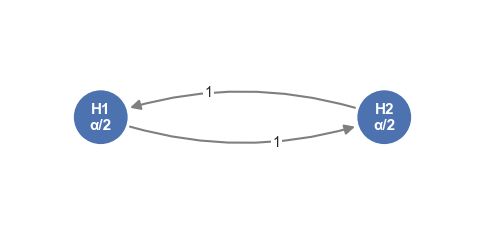

In [2]:
fig, ax = plt.subplots(figsize=(6, 2.8))
draw_graph(ax, np.array([0.5, 0.5]), np.array([[0, 1], [1, 0]]), ['H1', 'H2'], pos=[[0, 0], [1, 0]])
ax.set_ylim(-0.6, 0.6)
plt.show()

**Начальный вектор весов:** $\boldsymbol{\alpha} = (\alpha/2,\, \alpha/2)$ — бюджет разделён поровну.  
**Матрица переходов:**

$$
\mathbf{G} = \begin{pmatrix}
0 & 1 \\
1 & 0
\end{pmatrix}.
$$

**Интерпретация:**

Если отвергнута $H_1$, её уровень $\alpha/2$ полностью переходит к $H_2$ (ребро с весом 1), так что теперь $H_2$ будет проверяться на уровне $\alpha/2 + \alpha/2 = \alpha$. Если же первой будет отвергнута $H_2$, её уровень аналогично передаётся $H_1$. Таким образом, граф из двух вершин с симметричными рёбрами полностью кодирует процедуру Холма для $m = 2$. Как мы увидим далее, обобщение на $m$ гипотез потребует полносвязного графа с равными весами $g_{ij} = 1/(m-1)$, и это будет в точности процедура Холма.

### Алгоритм последовательного тестирования

Итак, у нас есть граф, заданный начальным вектором весов $\boldsymbol{\alpha}$ и матрицей переходов $\mathbf{G}$. Теперь мы должны формально определить, как именно с его помощью проверять гипотезы. Следующий алгоритм описывает простую итеративную процедуру, которая шаг за шагом отвергает гипотезы и обновляет граф.

---

**Входные данные**

- Множество элементарных нулевых гипотез $H_1,\dots,H_m$.
- Наблюдаемые p-значения $p_1,\dots,p_m$.
- Общий уровень значимости $\alpha \in (0,1)$.
- Начальное распределение $\boldsymbol{\alpha} = (\alpha_1,\dots,\alpha_m)$.
- Матрица переходов $\mathbf{G} = (g_{ij})$.

---

**Алгоритм**

1. **Инициализация**  
   1.1 Положим $I = \{1,\dots,m\}$ – множество индексов ещё не отвергнутых гипотез.

2. **Выбор гипотезы для проверки**  
   2.1. Вычислим для всех $i \in I$ с $\alpha_i > 0$ величину $p_i / \alpha_i$. Гипотезы с нулевым уровнем пока отвергнуть нельзя.  
   2.2. Выберем индекс $j \in I$, для которого это отношение минимально
   $$
   j = \arg\min_{i \in I} \frac{p_i}{\alpha_i}
   $$

3. **Проверка и остановка**  
   3.1. Если $p_j \le \alpha_j$, то **отвергаем** $H_j$.  
   3.2. Иначе – **останавливаем всю процедуру**: оставшиеся гипотезы не отвергаются.

4. **Обновление графа после отвержения**  
   После того как $H_j$ отвергнута, мы удаляем соответствующую вершину и перераспределяем её уровень $\alpha_j$ между оставшимися гипотезами. Формально:

   - Удаляем индекс $j$ из множества $I$:  $I \leftarrow I \setminus \{j\}$.

   - Обновляем уровни значимости оставшихся гипотез:   
   $$
   \alpha_\ell \leftarrow \alpha_\ell + \alpha_j \cdot g_{j\ell}, \qquad \ell \in I
   $$

   - Обновляем матрицу переходов:  
   $$
   g_{\ell k} \leftarrow \frac{g_{\ell k} + g_{\ell j} \cdot g_{jk}}{1 - g_{\ell j} \cdot g_{j\ell}}, \qquad \ell,k \in I,\ \ell \neq k
   $$

   Если $g_{\ell j} \cdot g_{j\ell} = 1$, знаменатель равен нулю, и новый вес ребра полагается равным 0.

5. **Повторение**  
   Если после обновления в $I$ ещё остались гипотезы ($|I| \ge 1$), возвращаемся к шагу 2, иначе завершаем процедуру.

**Свойства алгоритма**

1. **Строгий контроль FWER.**  
   Процедура гарантирует, что вероятность хотя бы одного ложного отклонения не превышает $\alpha$ при любых конфигурациях истинных и ложных нулевых гипотез. Доказательство опирается на связь с замкнутой процедурой тестирования – мы обсудим это в следующем разделе.

2. **Сокращённая процедура (shortcut).**  
   Алгоритм делает не более $m$ шагов и не требует явного перебора всех $2^m-1$ пересечений гипотез. Это чрезвычайно важно для практики.

3. **Независимость от порядка.**  
   Если на шаге 2 сразу несколько гипотез удовлетворяют условию $p_i \le \alpha_i$, окончательное множество отвергнутых гипотез не зависит от того, в каком порядке мы их отвергаем. Выбор «минимального отношения» – лишь удобный способ определить очерёдность.

**Простая иллюстрация: Холм для $m=2$**

Рассмотрим граф с $\boldsymbol{\alpha} = (\alpha/2, \alpha/2)$ и $g_{12}=g_{21}=1$. Пусть $p_1 < p_2$, и $p_1 \le \alpha/2$.

1. $p_1/\alpha_1 = \frac{p_1}{\alpha/2}$ минимально. Отвергаем $H_1$.
2. Удаляем вершину $H_1$. Уровень $\alpha/2$ полностью переходит к $H_2$:  
   $\alpha_2 \leftarrow \alpha/2 + (\alpha/2) \cdot 1 = \alpha$.
3. Теперь проверяем $H_2$: $p_2 \le \alpha$. Если да – отвергаем $H_2$, иначе – нет.

Это в точности процедура Холма: сначала проверяем более значимую гипотезу на уровне $\alpha/2$, затем оставшуюся – на полном $\alpha$.

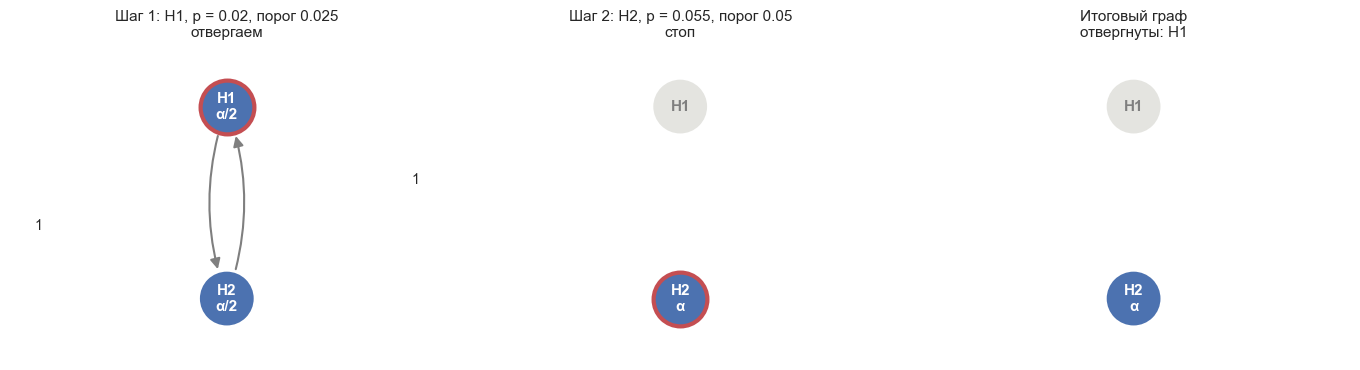

,Проверяем,p,Порог,Решение
Шаг,,,,
1,H1,0.020,0.025,отвергаем
2,H2,0.055,0.050,стоп


In [3]:
alpha = 0.05
m = 2
weights = np.full(m, 1 / m)      # начальные веса: поровну
G = np.array([[0, 1], [1, 0]])   # весь уровень отвергнутой гипотезы переходит к другой
p_vals = np.array([0.02, 0.055])

show_procedure(weights, G, p_vals, alpha)

### Связь с замкнутой процедурой тестирования

Ранее мы реализовали алгоритм, который шаг за шагом отвергает гипотезы и перераспределяет уровни значимости. Теперь мы строго докажем, что этот алгоритм контролирует групповую вероятность ошибки (FWER) на заданном уровне $\alpha$. Для этого мы погрузимся в конструкцию замкнутой процедуры тестирования (closed testing procedure) и покажем, что графический подход является её эффективной реализацией.

#### Замкнутая процедура тестирования

Рассмотрим множество элементарных нулевых гипотез $H_1, H_2, \ldots, H_m$ и обозначим $M = \{1,\ldots,m\}$. Для любого непустого подмножества индексов $I \subseteq \{1,\ldots,m\}$ определим **пересечение гипотез** $H_I = \bigcap_{i \in I} H_i$, которое утверждает, что все $H_i$ с $i \in I$ верны одновременно. Замкнутая процедура тестирования (Marcus et al., 1976) состоит из двух правил:

1. Для каждого $I \subseteq \{1,\ldots,m\}$ выбирается **локальный тест** уровня $\alpha$, который проверяет $H_I$. Локальный тест может отвергнуть $H_I$ или нет.
2. Элементарная гипотеза $H_i$ отвергается **тогда и только тогда**, когда для **всех** $I$, содержащих $i$, локальный тест отвергает $H_I$.

Процедура гарантирует сильный контроль FWER на уровне $\alpha$ при любых зависимостях между $p$-значениями, если каждый локальный тест корректен (т.е. вероятность ошибочно отвергнуть истинное пересечение не превышает $\alpha$). Доказательство чрезвычайно просто и изящно.

**Теорема (контроль FWER замкнутой процедурой).** Замкнутая процедура контролирует FWER на уровне $\alpha$ в сильном смысле.

**Доказательство.** Пусть $T \subseteq \{1,\ldots,m\}$ — непустое множество индексов истинных нулевых гипотез. Тогда FWER — это вероятность отвергнуть хотя бы одну $H_i$ с $i \in T$.

По построению, чтобы отвергнуть такую $H_i$, необходимо отвергнуть пересечение $H_T$ (так как $T$ содержит $i$, и условие требует отвержения всех пересечений, содержащих $i$). Следовательно, $\text{FWER} \le P$(локальный тест отвергает $H_T).$ Но $H_T$ — истинное пересечение (все гипотезы в $T$ верны), поэтому вероятность его ошибочного отвержения не превышает $\alpha$ по определению локального теста. Отсюда $\text{FWER} \le \alpha$.

В качестве примера рассмотрим случай с 4 гипотезами. Предположим, что подчеркнутые гипотезы были отклонены локальными тестами.

$$
\underline{H_{1234}} \\
\underline{H_{123}} \quad \underline{H_{124}} \quad \underline{H_{134}} \quad \underline{H_{234}} \\
\underline{H_{12}} \quad \underline{H_{13}} \quad \underline{H_{14}} \quad \underline{H_{23}} \quad H_{24} \quad H_{34} \\
\underline{H_1} \quad \underline{H_2} \quad H_3 \quad H_4
$$

* Здесь $H_1$ и $H_{23}$ отклонены замкнутой процедурой тестирования.
* $H_2$ не отклоняется замкнутой процедурой, так как локальный тест не отклоняет $H_{24}$.

К сожалению, наивная реализация требует провести $2^m - 1$ локальных тестов — уже при $m = 10$ это 1023 теста. Чтобы сделать процедуру практически применимой, необходимо строить локальные тесты специального вида, допускающие **сокращённую процедуру (shortcut)**, которая эквивалентна полному замкнутому тесту, но выполняет не более $m$ шагов.

#### Взвешенный тест Бонферрони как локальный тест

В графическом подходе для каждого $I \subseteq M$ используется взвешенный тест Бонферрони. Для $I$ задаются неотрицательные веса $w_i(I)$, $i \in I$, такие что $\sum_{i \in I} w_i(I) \le 1$. Тогда пересечение $H_I$ отвергается, если существует $i \in I$, для которого $p_i \le w_i(I) \cdot \alpha$. Такой тест имеет уровень $\alpha$ благодаря неравенству Бонферрони:

$$
P_{H_I}\left( \bigcup_{i \in I} \{ p_i \le w_i(I)\alpha \} \right) \le \sum_{i \in I} P_{H_I}(p_i \le w_i(I)\alpha) \le \sum_{i \in I} w_i(I)\alpha \le \alpha.
$$

Таким образом, локальный тест корректен для любого $I$.

**Построение весов из графа**

Начальный граф $(\boldsymbol{\alpha}, \mathbf{G})$ задаёт семейство весов $\{w_i(I)\}$ для всех $I \subseteq M$. Чтобы получить веса для $I$, начинаем с полного графа и поочерёдно удаляем все вершины $j \notin I$. Удаление вершины $j$ из текущего множества $S$ переводит его в $S' = S \setminus \{j\}$ по уже знакомым правилам:

$$
\alpha_\ell(S') = \alpha_\ell(S) + \alpha_j(S)\, g_{j\ell}(S), \quad \ell \in S',
$$

$$
g_{\ell k}(S') = \frac{g_{\ell k}(S) + g_{\ell j}(S)\, g_{jk}(S)}{1 - g_{\ell j}(S)\, g_{j\ell}(S)}, \quad \ell,k \in S',\ \ell \neq k.
$$

В статье доказано, что итоговые уровни не зависят от порядка удаления вершин. Полагая $w_i(I) = \alpha_i(I)/\alpha$, получаем $\sum_{i \in I} w_i(I) \le 1$.

#### Построение сокращённой процедуры

**Условие монотонности**

Ключевое свойство, обеспечивающее существование shortcut, — **монотонность** весов:

$$w_i(J) \ge w_i(I) \quad \text{для всех } J \subseteq I,\ i \in J.$$

В терминах исходных $\alpha_i(I)$ это означает, что при удалении гипотез (переходе от большего пересечения к меньшему) оставшиеся гипотезы могут только увеличить свою долю уровня значимости. В той же статье строго доказано, что веса, порождённые алгоритмом, представленным выше, удовлетворяют условию монотонности. Интуитивно это ясно: удаляя гипотезу, мы перераспределяем её уровень на оставшиеся, поэтому их веса не уменьшаются.

**Консонантность и сокращённая процедура**

Замкнутая процедура называется **консонантной**, если из отвержения пересечения $H_I$ следует, что найдётся элементарная гипотеза $H_j$, $j \in I$, которая отвергается локальными тестами **всех** подмножеств $J \subseteq I$, содержащих $j$. Иными словами, отвержение пересечения сразу указывает на конкретную гипотезу, ответственную за него.

Взвешенный тест Бонферрони консонантен именно благодаря **монотонности весов**. Пусть $H_I$ отвергнуто, то есть $\min_{i \in I} p_i / w_i(I) \le \alpha$, и минимум достигается на $j$. Тогда $p_j \le w_j(I)\,\alpha$. Для любого $J \subseteq I$ с $j \in J$ монотонность даёт $w_j(J) \ge w_j(I)$, поэтому $p_j \le w_j(J)\,\alpha$, и $H_J$ тоже отвергается.

Без монотонности это рассуждение не работает: при уменьшении пересечения вес $j$ мог бы упасть, и отвержения бы не произошло. Поэтому монотонность — ключевое свойство, а для графов она выполняется автоматически.

**От консонантности к сокращённой процедуре**

Представим, что мы применяем замкнутую процедуру наивно: перебираем все $I \subseteq M$ в порядке возрастания размера, проверяем, отвергается ли $H_I$ по Бонферрони, и затем формируем множество отвергнутых элементарных гипотез согласно правилу: $H_i$ отвергается, если **для всех** $I$, содержащих $i$, $H_I$ отвергнуто.

Консонантность позволяет заменить эту экспоненциальную проверку последовательным алгоритмом, работающим **только с текущим множеством ещё не отвергнутых гипотез**. Вот логика shortcut:

1. В начальный момент у нас есть всё множество $M$ и веса $w_i(M)$. Поскольку пересечение $H_M$ соответствует проверке сразу всех гипотез, его локальный тест – это обычный взвешенный Бонферрони. Отвергаем $H_j$, на которой достигается минимум $p_i / w_i(M)$, если $p_j \leq w_j(M)\,\alpha$.
2. Если такая $H_j$ найдена, то **консонантность гарантирует**, что для любого другого пересечения $I$, содержащего $j$, локальный тест тоже сработает (поскольку удаление других гипотез может только увеличить вес $j$). Следовательно, $H_j$ будет отвергнута и в полной замкнутой процедуре.
3. Мы удаляем $H_j$ из рассмотрения и переходим к множеству $M' = M \setminus \{j\}$. Для этого множества мы **заново вычисляем веса** $w_i(M')$ по тем же правилам удаления вершин. Монотонность гарантирует, что для всех оставшихся $i$ выполняется $w_i(M') \geq w_i(M)$. Теперь мы снова применяем взвешенный Бонферрони к $H_{M'}$ – и так до тех пор, пока на очередном шаге ни одна гипотеза не будет отвергнута.
4. Процедура останавливается, когда $\min_{i\in I} p_i/\alpha_i(I) > 1$. Все гипотезы, отвергнутые на предыдущих шагах, считаются отвергнутыми.

Эта последовательная процедура, как доказано в Hommel, Bretz & Maurer (2007), **эквивалентна полной замкнутой процедуре** и, следовательно, контролирует FWER. При этом она требует не более $m$ шагов и избавляет от необходимости явно выписывать и проверять $2^m-1$ пересечений.

Теперь видно, что алгоритм, представленный до этого, есть не что иное, как этот shortcut:

- **Шаг 2** (выбор $j$ с минимальным $p_i/\alpha_i$) – ровно то же самое, что поиск индекса, доставляющего минимум в локальном тесте Бонферрони для текущего пересечения $H_I$.
- **Шаг 3** (проверка $p_j \leq \alpha_j$) – отвержение $H_j$ на уровне $\alpha_j(I)$, что в силу консонантности означает отвержение $H_j$ в замкнутой процедуре.
- **Шаг 4** (обновление графа) – пересчёт весов для нового множества $I \setminus \{j\}$.

Таким образом, предлагаемый алгоритм напрямую реализует замкнутую процедуру тестирования с взвешенными бонферрониевскими тестами, гарантируя строгий контроль FWER без каких-либо дополнительных предположений о структуре зависимости $p$-значений.

#### Пример

Пусть
* $m = 4$
* общий уровень $\alpha = 0.05$
* $\alpha = (0.01,\; 0.02,\; 0.01,\; 0.01)$
* $p$-значения $= (0.008,\; 0.03,\; 0.009,\; 0.10)$

* Матрица переходов $G$:

$$
\mathbf{G} = \begin{pmatrix}
0 & 0.5 & 0.5 & 0\\
0 & 0 & 0 & 1\\
0 & 0 & 0 & 1\\
0 & 0 & 0 & 0
\end{pmatrix}
$$

___

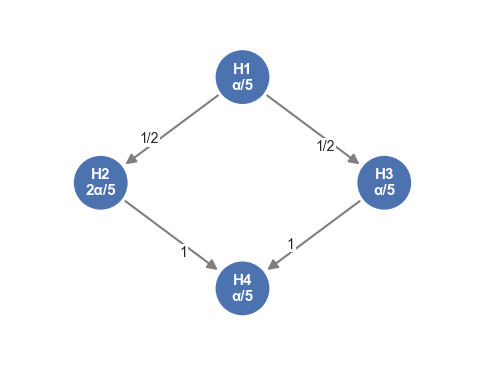

In [4]:
example_weights = np.array([0.01, 0.02, 0.01, 0.01]) / 0.05  # веса w_i = α_i / α
example_G = np.array([[0, 0.5, 0.5, 0],
                      [0, 0, 0, 1],
                      [0, 0, 0, 1],
                      [0, 0, 0, 0]])
example_p = np.array([0.008, 0.03, 0.009, 0.10])

fig, ax = plt.subplots(figsize=(6, 4.5))
draw_graph(ax, example_weights, example_G, ['H1', 'H2', 'H3', 'H4'], pos=[[0, 1], [-1, 0], [1, 0], [0, -1]])
plt.show()

**Шаг 0. Исходное пересечение $H_{\{1,2,3,4\}}$**

* Считаем веса для $I_0 = \{1,2,3,4\}$: $w_i = \alpha_i / \alpha = (0.01/0.05,\; 0.02/0.05,\; 0.01/0.05,\; 0.01/0.05) = (0.2,\;0.4,\;0.2,\;0.2)$.

* Локальный взвешенный тест Бонферрони для $H_{I_0}$:
  * вычисляем для каждой гипотезы значение $p_i / \alpha_i$

  $$
  \frac{0.008}{0.01}=0.8,\quad
  \frac{0.03}{0.02}=1.5,\quad
  \frac{0.009}{0.01}=0.9,\quad
  \frac{0.10}{0.01}=10.
  $$
    
  * Условие отвержения пересечения: $\min_i p_i/w_i \le \alpha$ ~ $\min_i p_i / \alpha_i \le 1$.
  
    У $H_1$ минимальный коэффициент ($0.8$), и т.к. $0.8 \le 1$, то пересечение $H_{\{1,2,3,4\}}$ **отвергается**.  
* По свойству консонантности $H_1$ может быть отвергнута на уровне $\alpha_1(I_0)=0.01$, ведь $p_1 \le w_1(I_0) \cdot \alpha \;(0.008 \le 0.2 \cdot 0.05)$.

**Итог шага:** отвергаем $H_1$, удаляем её из множества и идём на следующую итерацию.

**Шаг 1. Удаляем $H_1$, обновляем веса для $I_1 = \{2,3,4\}$**

Перераспределяем $\alpha_1=0.01$ согласно $G$ ($g_{12}=0.5$, $g_{13}=0.5$):
- $\alpha_2^{\text{new}} = 0.02 + 0.01\cdot 0.5 = 0.025$
- $\alpha_3^{\text{new}} = 0.01 + 0.01\cdot 0.5 = 0.015$
- $\alpha_4^{\text{new}} = 0.01$ (без изменений, т.к. из $H_1$ нет перехода в $H_4$)

**Шаг 2. Тестируем пересечение $H_{\{2,3,4\}}$**

* Считаем новые веса для $I_1$: $w_i(I_1) = \alpha_i^{\text{new}} / \alpha$: $(0.025/0.05=0.5,\; 0.015/0.05=0.3,\; 0.01/0.05=0.2)$.

* Локальный взвешенный тест Бонферрони для $H_{I_1}$:
  * вычисляем для каждой гипотезы значение $p_i / \alpha_i$

  $$
  \frac{p_2}{\alpha_2^{\text{new}}} = \frac{0.03}{0.025}=1.2,\quad
  \frac{p_3}{\alpha_3^{\text{new}}} = \frac{0.009}{0.015}=0.6,\quad
  \frac{p_4}{\alpha_4^{\text{new}}} = \frac{0.10}{0.01}=10.
  $$
    
  * Условие отвержения пересечения: $\min_i p_i/w_i \le \alpha$ ~ $\min_i p_i / \alpha_i \le 1$.
  
    У $H_3$ минимальный коэффициент ($0.6$), и т.к. $0.6 \le 1$, то пересечение $H_{\{2,3,4\}}$ **отвергается**.  
* По свойству консонантности $H_3$ может быть отвергнута на уровне $\alpha_3(I_1)=0.015$, ведь $p_3 \le w_3(I_1) \cdot \alpha \;(0.009 \le 0.3 \cdot 0.05)$.

**Итог шага:** отвергаем $H_3$, удаляем её из множества и идём на следующую итерацию.

**Шаг 3. Удаляем $H_3$, обновляем веса для $I_2 = \{2,4\}$**

Из $H_3$ был переход $g_{34}=1.0$, поэтому вес $H_3$ ($0.015$) целиком переходит к $H_4$:
- $\alpha_2$ остаётся $0.025$ (нет переходов из $H_3$ в $H_2$)
- $\alpha_4^{\text{new}} = 0.01$ $+ 0.015\cdot 1.0 = 0.025$

**Шаг 4. Тестируем пересечение $H_{\{2,4\}}$**

* Считаем новые веса для $I_2$: $w_i(I_2) = \alpha_i^{\text{new}} / \alpha$: $(0.025/0.05=0.5,\; 0.025/0.05=0.5)$.

* Локальный взвешенный тест Бонферрони для $H_{I_2}$:
  * вычисляем для каждой гипотезы значение $p_i / \alpha_i$

  $$
  \frac{p_2}{\alpha_2} = \frac{0.03}{0.025}=1.2,\quad
  \frac{p_4}{\alpha_4} = \frac{0.10}{0.025}=4.0.
  $$
    
  * Условие отвержения пересечения: $\min_i p_i/w_i \le \alpha$ ~ $\min_i p_i / \alpha_i \le 1$.
  
    У $H_2$ минимальный коэффициент ($1.2$), и т.к. $1.2 > 1$, то пересечение $H_{\{2,4\}}$ **не отвергается**.  

**Итог шага:** Процедура останавливается.

**Итог**

| Шаг | Рассматриваемое множество $I$ | Отвергается? | Какая $H_i$ отвергается (минимум $p_i/\alpha_i$) |
|-----|-------------------------------|--------------|------------------------------------------------|
| 0   | $\{1,2,3,4\}$                 | Да ($0.8\le1$) | $H_1$ ($p_1/\alpha_1=0.8$)                    |
| 1   | $\{2,3,4\}$                   | Да ($0.6\le1$) | $H_3$ ($p_3/\alpha_3=0.6$)                    |
| 2   | $\{2,4\}$                     | Нет ($1.2>1$) | –                                              |

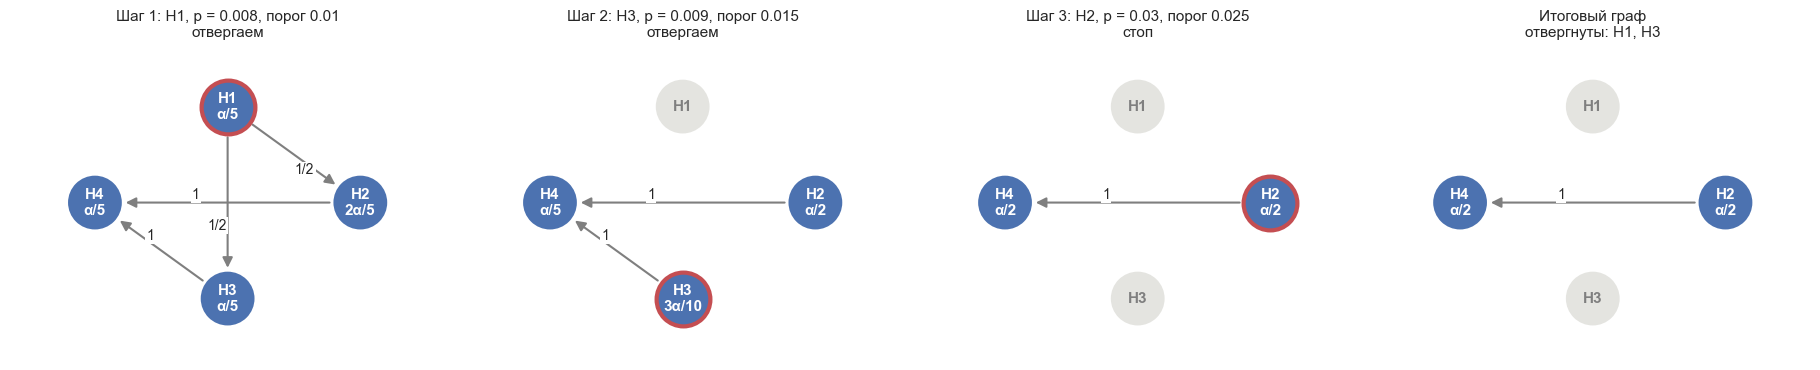

,Проверяем,p,Порог,Решение
Шаг,,,,
1,H1,0.008,0.010,отвергаем
2,H3,0.009,0.015,отвергаем
3,H2,0.030,0.025,стоп


In [5]:
show_procedure(example_weights, example_G, example_p, alpha)

**Проверка замкнутой процедурой**

Полная замкнутая процедура должна проверить все $2^4-1=15$ пересечений, а сокращённая процедура сделала всего 3 проверки. Убедимся кодом, что результат тот же. Дополнительно сверим обе процедуры на случайных графах, а граф Холма сверим со `statsmodels`.

In [6]:
print('Сокращённая процедура:', sorted(graph_test(example_weights, example_G, example_p, alpha)))
print('Полная замкнутая:     ', closed_test(example_weights, example_G, example_p, alpha))

rng = np.random.default_rng(1)
mismatches = 0
for _ in range(1000):
    m = rng.integers(2, 7)
    random_weights = rng.dirichlet(np.ones(m) * 0.5) * rng.choice([1, 0.8])
    random_G = np.zeros((m, m))
    for i in range(m):
        others = [j for j in range(m) if j != i]
        random_G[i, others] = rng.dirichlet(np.ones(m - 1) * 0.5) * rng.choice([1, 0.7])
    random_p = rng.beta(0.4, 3, m) * 0.3
    mismatches += sorted(graph_test(random_weights, random_G, random_p)) != closed_test(random_weights, random_G, random_p)
print('Расхождений на 1000 случайных графов:', mismatches)

mismatches = 0
for _ in range(200):
    m = rng.integers(2, 12)
    random_p = rng.beta(0.3, 3, m)
    full_G = np.full((m, m), 1 / (m - 1))
    np.fill_diagonal(full_G, 0)
    decisions = np.zeros(m, dtype=bool)
    decisions[graph_test(np.full(m, 1 / m), full_G, random_p)] = True
    mismatches += not np.array_equal(decisions, multipletests(random_p, 0.05, 'holm')[0])
print('Расхождений графа Холма со statsmodels:', mismatches)

Сокращённая процедура: [0, 2]
Полная замкнутая:      [0, 2]


Расхождений на 1000 случайных графов: 0


Расхождений графа Холма со statsmodels: 0


## Детальный разбор ключевых примеров

Теперь, вооружённые полным пониманием алгоритма и его теоретической базы, перейдём к конкретным примерам. Начнём с самого простого, чтобы убедиться: классическая поправка Бонферрони – это частный случай графического подхода.

### Поправка Бонферрони как вырожденный граф

**Построение графа**

Пусть у нас $m$ элементарных гипотез $H_1,\dots,H_m$.
* Назначим начальные веса **поровну**: $\alpha_i = \frac{\alpha}{m}, \qquad i=1,\dots,m.$ Очевидно, $\sum_i \alpha_i = \alpha$.

* Зададим матрицу переходов $\mathbf{G}$: $g_{ij} = 0 \quad \text{для всех } i,j.$ Это означает, что из каждой вершины не исходит ни одного ребра – граф представляет собой $m$ изолированных узлов. Сумма весов исходящих рёбер равна $0 \le 1$, условие регулярности выполнено.

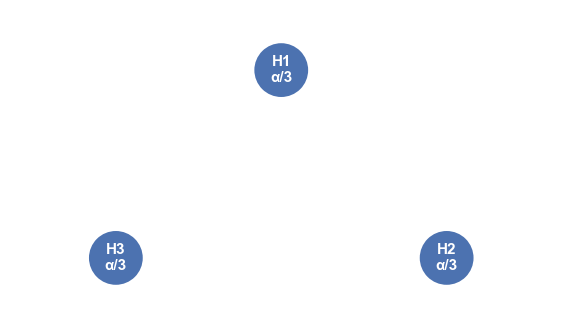

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
draw_graph(ax, np.full(3, 1 / 3), np.zeros((3, 3)), ['H1', 'H2', 'H3'])
plt.show()

**Применение Алгоритма**

Запустим на таком графе Алгоритм с наблюдаемыми p-значениями $p_1,\dots,p_m$.

1. **Инициализация:** $I = \{1,\dots,m\}$, $\alpha_i = \alpha/m$ для всех $i\in I$.
2. **Выбор гипотезы:** находим $j$ с наименьшим отношением $p_i / \alpha_i$. Поскольку все $\alpha_i$ одинаковы, это эквивалентно выбору гипотезы с **наименьшим p-значением**.
3. **Проверка:** если $p_j \le \alpha_j = \alpha/m$, отвергаем $H_j$; иначе **стоп**.
4. **Обновление графа после отвержения $H_j$:**
   - Удаляем $j$ из $I$.
   - Для всех $\ell \in I$:
  $$
  \alpha_\ell \leftarrow \alpha_\ell + \alpha_j \cdot g_{j\ell} = \alpha_\ell + \alpha_j \cdot 0 = \alpha_\ell.
  $$
     Уровни оставшихся гипотез **не меняются**.
   - Матрица переходов остаётся нулевой.
5. **Повтор:** возвращаемся к шагу 2 с тем же набором $\alpha_i = \alpha/m$, но с уменьшенным множеством $I$. На следующей итерации снова будет выбрана гипотеза с минимальным $p$ среди оставшихся, и она будет проверена на том же уровне $\alpha/m$.

Таким образом, процедура последовательно перебирает гипотезы в порядке возрастания p-значений и отвергает их до тех пор, пока очередное p-значение не превысит **один и тот же порог** $\alpha/m$. Это в точности **поправка Бонферрони**: отвергаются все гипотезы с $p_i \le \alpha/m$.

При этом, в отличие от других процедур, уровень значимости не перераспределяется – каждое сравнение происходит на изначально выделенном кусочке $\alpha/m$, а освободившийся - сгорает, и именно поэтому поправка Бонферрони консервативнее процедур, использующих этот уровень повторно.

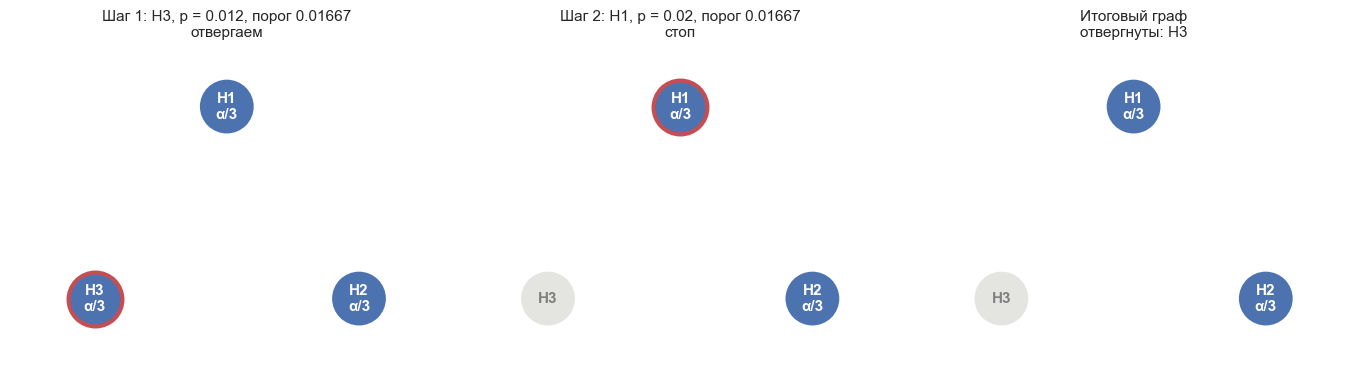

,Проверяем,p,Порог,Решение
Шаг,,,,
1,H3,0.012,0.01667,отвергаем
2,H1,0.020,0.01667,стоп


In [8]:
m = 3
bonferroni_weights = np.full(m, 1 / m)
bonferroni_G = np.zeros((m, m))        # рёбер нет
p_vals = np.array([0.02, 0.055, 0.012])

show_procedure(bonferroni_weights, bonferroni_G, p_vals, alpha)

### Процедура Холма как граф

**Построение графа**

Пусть у нас $m$ элементарных гипотез $H_1,\dots,H_m$.
* Назначим начальные веса **поровну**: $\alpha_i = \frac{\alpha}{m}, \qquad i=1,\dots,m.$ Очевидно, $\sum_i \alpha_i = \alpha$.

* Зададим матрицу переходов $\mathbf{G}$: $g_{ij} = \frac{1}{m-1}\;, g_{ii} = 0$. Сумма весов исходящих рёбер равна $\sum_{j=1}^m g_{ij} = (m-1)\cdot\frac{1}{m-1} = 1$, условие регулярности выполнено.

Таким образом, получается **полносвязный ориентированный граф**, в котором от каждой вершины к каждой другой идёт ребро с весом $1/(m-1)$.

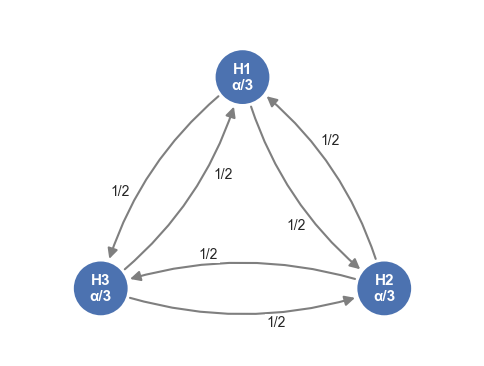

In [9]:
m = 3
holm_weights = np.full(m, 1 / m)
holm_G = np.full((m, m), 1 / (m - 1))
np.fill_diagonal(holm_G, 0)

fig, ax = plt.subplots(figsize=(6, 4.5))
draw_graph(ax, holm_weights, holm_G, ['H1', 'H2', 'H3'])
plt.show()

**Классическая процедура Холма**

Прежде чем запускать алгоритм, вспомним стандартную формулировку Холма:

1. Упорядочить p-значения: $p_{(1)} \le p_{(2)} \le \dots \le p_{(m)}$ с соответствующими гипотезами $H_{(1)},\dots,H_{(m)}$.
2. Найти наименьший индекс $i$, для которого $p_{(i)} > \frac{\alpha}{m-i+1}$.
3. Отвергнуть все гипотезы $H_{(1)},\dots,H_{(i-1)}$.

Иными словами, самая значимая гипотеза тестируется на уровне $\alpha/m$, следующая — на $\alpha/(m-1)$, и т.д. Как только встречается гипотеза, не преодолевающая свой барьер, процедура останавливается.

**Работа Алгоритма на графе Холма**

Покажем, что применение Алгоритма к построенному графу даёт в точности те же результаты. Возьмём $m=3$, $\alpha=0.05$ и p-значения $= (0.02, 0.055, 0.012)$

**Шаг 1.** Инициализация: $I = \{1,2,3\}$

  * $\alpha_i = \alpha/3 \approx 0.0167$

  * Вычисляем отношения:

  $$
  \frac{p_1}{\alpha_1} = \frac{0.02}{0.0167} \approx 1.20\qquad
  \frac{p_2}{\alpha_2} = \frac{0.055}{0.0167} \approx 3.30\qquad
  \frac{p_3}{\alpha_3} = \frac{0.012}{0.0167} \approx 0.72
  $$

  * Минимальное отношение у $H_3$: $p_3 = 0.012 \le 0.0167$ — **отвергаем и удаляем из графа $H_3$**

  * $\alpha/3$ перераспределяется поровну между $H_1$ и $H_2$ (потому что $g_{31} = g_{32} = 1/2$):

$$
\alpha_1 \leftarrow \frac{\alpha}{3} + \frac{\alpha}{3}\cdot\frac{1}{2} = \frac{\alpha}{2} = 0.025
$$
$$
\alpha_2 \leftarrow \frac{\alpha}{3} + \frac{\alpha}{3}\cdot\frac{1}{2} = \frac{\alpha}{2} = 0.025
$$

  * Пересчитывается $G$: $g_{12} = g_{21} = 1$

**Шаг 2.** $I = \{1,2\}$

  * Локальные уровни: $\alpha_1=\alpha_2=0.025$.

  * Вычисляем отношения:
$$
\frac{p_1}{\alpha_1} = \frac{0.02}{0.025} = 0.8 \qquad
\frac{p_2}{\alpha_2} = \frac{0.055}{0.025} = 2.2
$$

  * Минимальное у $H_1$: $p_1 = 0.02 \le 0.025$ — **отвергаем и удаляем из графа $H_1$**.

  * $\alpha/2$ переходит к $H_2$. Получаем $\alpha_2 = 0.025 + 0.025 = 0.05$.

**Шаг 3.** Осталась одна $H_2$, проверяем: $p_2 = 0.055 > 0.05$ — **не отвергаем**.

**Итого**

Отвергнуты $H_3$ и $H_1$ — ровно те гипотезы, которые были бы отвергнуты классической процедурой Холма (на первом шаге $p_{(1)}=0.012 \le 0.05/3$, на втором $p_{(2)}=0.02 \le 0.05/2$, на третьем $p_{(3)}=0.055 > 0.05/1$).

**Почему граф с равными весами даёт процедуру Холма?**

Секрет кроется в том, что на каждом шаге после удаления $k$ гипотез веса оставшихся становятся одинаковыми и равными $\alpha/(m-k)$. Действительно, полносвязный граф с равными переходами $1/(m-1)$ обладает свойством «забывания»: откуда бы ни пришёл уровень значимости, он всегда равномерно распределяется между всеми оставшимися вершинами. В результате на $k$-м шаге каждая из $m-k+1$ оставшихся гипотез имеет локальный уровень $\alpha/(m-k+1)$, что в точности совпадает с порогами Холма.

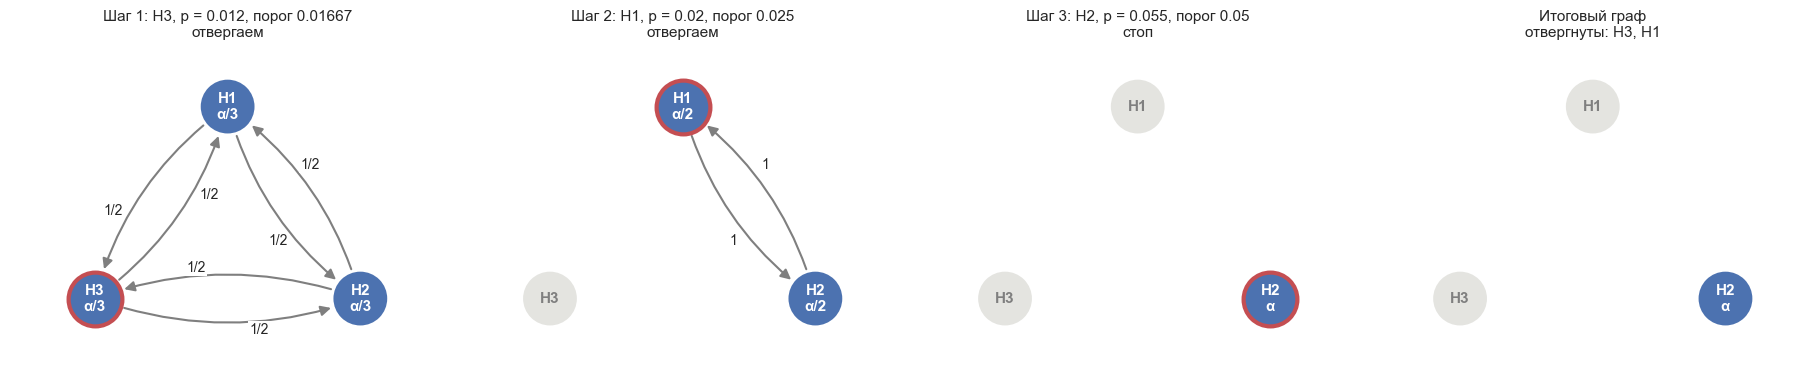

,Проверяем,p,Порог,Решение
Шаг,,,,
1,H3,0.012,0.01667,отвергаем
2,H1,0.020,0.02500,отвергаем
3,H2,0.055,0.05000,стоп


In [10]:
show_procedure(holm_weights, holm_G, p_vals, alpha)

### Фиксированная последовательность

Самый жёсткий вариант иерархии — проверять гипотезы строго по порядку. Весь уровень $\alpha$ стоит на первой гипотезе, а рёбра с весом 1 образуют цепочку. Если очередная гипотеза не отвергнута, все следующие остаются с нулевым уровнем и не могут быть отвергнуты, даже с очень маленькими p-значениями.

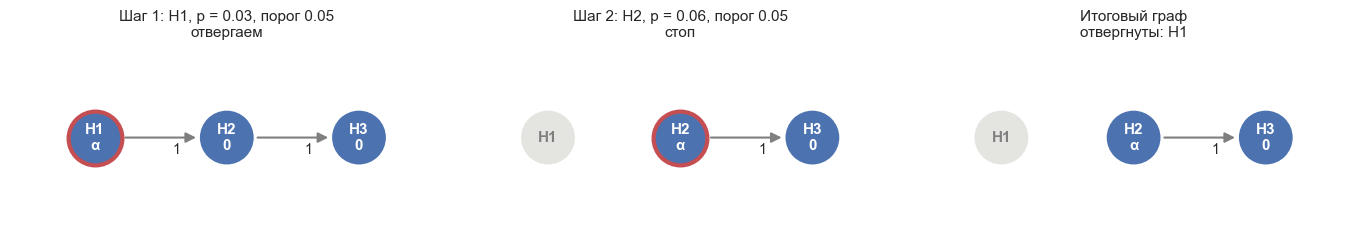

,Проверяем,p,Порог,Решение
Шаг,,,,
1,H1,0.03,0.05,отвергаем
2,H2,0.06,0.05,стоп


In [11]:
sequence_weights = np.array([1.0, 0, 0])
sequence_G = np.array([[0, 1, 0], [0, 0, 1], [0, 0, 0]])

show_procedure(sequence_weights, sequence_G, np.array([0.03, 0.06, 0.0001]), alpha, pos=[[0, 0], [1, 0], [2, 0]], panel_height=2.6)

### Гейткипинг для двух семейств

Теперь мы переходим к одному из наиболее важных приложений графического подхода — **гейткипингу** (gatekeeping). Этот метод незаменим, когда гипотезы естественно группируются в первичные и вторичные семейства, и вторичные разрешается проверять только после успеха первичных.

**Мотивация: зачем нужен гейткипинг?**

Представьте типичный A/B-тест в продукте: вы тестируете новый алгоритм рекомендаций. У вас есть **основная метрика** — выручка на пользователя (revenue), и несколько **охранных метрик** — CTR главной страницы, удержание через неделю, время до первого заказа. Бизнес-логика требует:

1. Сначала доказать, что новая рекомендательная система **увеличивает** revenue по сравнению с контролем.
2. Только после этого проверить, что она **не ухудшает** охранные метрики.

Если revenue не показала значимого прироста, мы не хотим тратить статистический бюджет на проверку охранных метрик — такой вариант всё равно не пойдёт в прод. Но если метрика значимо выросла, мы готовы проверить безопасность, и здесь нам нужно иметь достаточный уровень значимости для этих вторичных тестов.

Аналогичная ситуация возникает в клинических испытаниях: первичные конечные точки (например, выживаемость) должны быть доказаны до того, как переходить к анализу вторичных (качество жизни, биомаркеры). Регуляторы требуют, чтобы FWER строго контролировался на уровне $\alpha$ для **всего** исследования, включая обе группы гипотез.

Классический гейткипинг формализует эту логику: первичное семейство $\mathcal{F}_1 = \{H_1, H_2\}$ получает весь уровень $\alpha$, а вторичное семейство $\mathcal{F}_2 = \{H_3, H_4\}$ изначально имеет нулевые уровни. Уровень переходит от первичных гипотез к вторичным **только после того, как соответствующие первичные гипотезы отвергнуты**. В **последовательном** гейткипинге вторичные гипотезы открываются только после отвержения всех первичных. Мы разберём **параллельный** вариант: каждая отвергнутая первичная гипотеза сразу передаёт свою долю вторичному семейству.

**Построение графа**

Пусть у нас $m=4$ элементарных гипотез $H_1,\dots,H_4$
* Назначим начальные веса: $\boldsymbol{\alpha} = \left( \frac{\alpha}{2},\ \frac{\alpha}{2},\ 0,\ 0 \right)$

* Зададим матрицу переходов $\mathbf{G}$:
$$
\mathbf{G} = \begin{pmatrix}
0 & 0 & 1/2 & 1/2 \\
0 & 0 & 1/2 & 1/2 \\
0 & 0 & 0 & 1 \\
0 & 0 & 1 & 0
\end{pmatrix}
$$

  Матрица переходов $\mathbf{G}$ отражает правило: после отвержения первичной гипотезы её уровень делится поровну между двумя вторичными. А после отвержения вторичной — полностью передаётся другой вторичной. Рёбер между первичными и от вторичных к первичным нет:

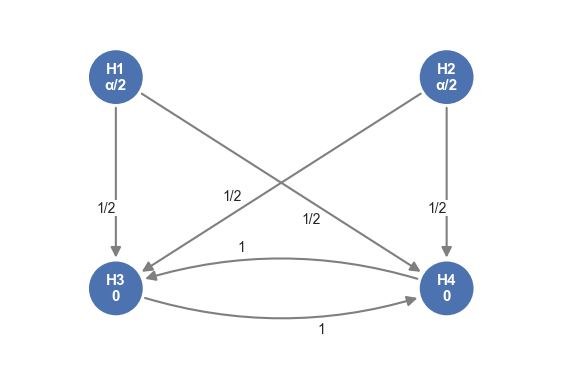

In [12]:
gate_weights = np.array([0.5, 0.5, 0, 0])
gate_G = np.array([[0, 0, 1/2, 1/2],
                   [0, 0, 1/2, 1/2],
                   [0, 0, 0, 1],
                   [0, 0, 1, 0]])
gate_pos = [[0, 1], [1.4, 1], [0, 0], [1.4, 0]]  # первичные гипотезы сверху

fig, ax = plt.subplots(figsize=(7, 4.5))
draw_graph(ax, gate_weights, gate_G, ['H1', 'H2', 'H3', 'H4'], pos=gate_pos)
plt.show()

**Пример**

Пусть $\alpha=0.05$  и $p$-значения $=(0.02,0.04,0.01,0.015)$

**Шаг 1.** $I = \{1,2,3,4\}$
* Локальные уровни: $\alpha_1=\alpha_2=0.025$, $\alpha_3=\alpha_4=0$  
* Сравниваем $p_i/\alpha_i$: для $H_3, H_4$ деление на ноль, поэтому они не выбираются. Выбираем минимум среди $(H_1, H_2)$:
$$
\frac{p_1}{\alpha_1} = \frac{0.02}{0.025} = 0.8 \qquad
\frac{p_2}{\alpha_2} = \frac{0.04}{0.025} = 1.6
$$

* Минимальное отношение у  $H_1$. $p_1 = 0.02 \le 0.025$ — **отвергаем и удаляем из графа $H_1$**

* Уровень $\alpha_1 = \alpha/2 = 0.025$ распределяется поровну между $H_3$ и $H_4$ (веса $g_{13}=g_{14}=1/2$):

$$
\alpha_2 \leftarrow \alpha_2 = 0.025
$$
$$
\alpha_3 \leftarrow \alpha_3 + \alpha_1 \cdot g_{13} = 0 + 0.025 \cdot \frac{1}{2} = 0.0125
$$
$$
\alpha_4 \leftarrow \alpha_4 + \alpha_1 \cdot g_{14} = 0 + 0.025 \cdot \frac{1}{2} = 0.0125
$$

**Шаг 2.** $I = \{2,3,4\}$.  
  * Локальные уровни: $\alpha_2 = 0.025$, $\alpha_3 = 0.0125$, $\alpha_4 = 0.0125$

  * Вычисляем отношения:
$$
\frac{p_2}{\alpha_2} = \frac{0.04}{0.025} = 1.6,\quad
\frac{p_3}{\alpha_3} = \frac{0.01}{0.0125} = 0.8,\quad
\frac{p_4}{\alpha_4} = \frac{0.015}{0.0125} = 1.2.
$$
  * Минимальное у $H_3$: $p_3 = 0.01 \le 0.0125$ — **отвергаем и удаляем из графа $H_3$**

* Уровень $\alpha_3 = 0.0125$ целиком переходит к $H_4$:

$$
\alpha_2 \leftarrow \alpha_2 = 0.025 \quad
$$
$$
\alpha_4 \leftarrow \alpha_4 + \alpha_3 \cdot g_{34} = 0.0125 + 0.0125 \cdot 1 = 0.025.
$$

**Шаг 3.** $I = \{2,4\}$.  

  * Локальные уровни: $\alpha_2 = 0.025$, $\alpha_4 = 0.025$
  * Вычисляем отношения:
$$
\frac{p_2}{\alpha_2} = \frac{0.04}{0.025} = 1.6,\qquad
\frac{p_4}{\alpha_4} = \frac{0.015}{0.025} = 0.6.
$$
  * Минимум у $H_4$: $p_4 = 0.015 \le 0.025$ — **отвергаем и удаляем из графа $H_4$**

  * Уровень $\alpha_4 = 0.025$ **теряется**, т.к. не осталось никаких гипотез из $I $, куда бы мог перейти этот уровень.

**Шаг 4.**  Осталась только $H_2$: проверяем $p_2 = 0.04 > 0.025$ — **не отвергаем**.

**Итого**

Отвергнуты $H_1, H_3, H_4$. Гипотеза $H_2$ не отвергнута, хотя её p-значение $0.04$ меньше $\alpha=0.05$. Уровень значимости, высвободившийся после успеха вторичных гипотез, не смог вернуться к первичной $H_2$ из-за отсутствия обратного ребра.

**Улучшение с помощью ε-рёбер**

Чтобы избежать проблемы, замеченной выше, предлагается изящное решение: добавить от вторичных гипотез обратные рёбра к первичным с **бесконечно малым весом** $\varepsilon$. Смысл в том, что пока во вторичном семействе есть неотвергнутые гипотезы, уровень передаётся внутри него, а $\varepsilon$-ребро практически ничего не отдаёт (в пределе $\varepsilon \to 0$). Но когда **все вторичные** гипотезы отвергнуты, у последней из них остаются только $\varepsilon$-рёбра, и после пересчёта их вес становится равен $1$. Это позволяет уровню, накопленному во вторичном семействе, вернуться к неотвергнутым первичным гипотезам.

Модифицированная матрица переходов $G$ тогда будет выглядеть следующим образом:

$$
\mathbf{G}_\varepsilon = \begin{pmatrix}
0 & 0 & 1/2 & 1/2 \\
0 & 0 & 1/2 & 1/2 \\
\varepsilon & \varepsilon & 0 & 1-2\varepsilon \\
\varepsilon & \varepsilon & 1-2\varepsilon & 0
\end{pmatrix}.
$$

Теперь после отвержения $H_1, H_3, H_4$ $\varepsilon$-ребро $H_4 \to H_2$ становится единственным путём, и **весь** уровень $0.025$ передаётся $H_2$. Тогда $\alpha_2$ становится $0.025 + 0.025 = 0.05$, и $p_2 = 0.04 \le 0.05$ — $H_2$ отвергается! В результате отвергнуты все четыре гипотезы.

#### Обычный гейткипинг

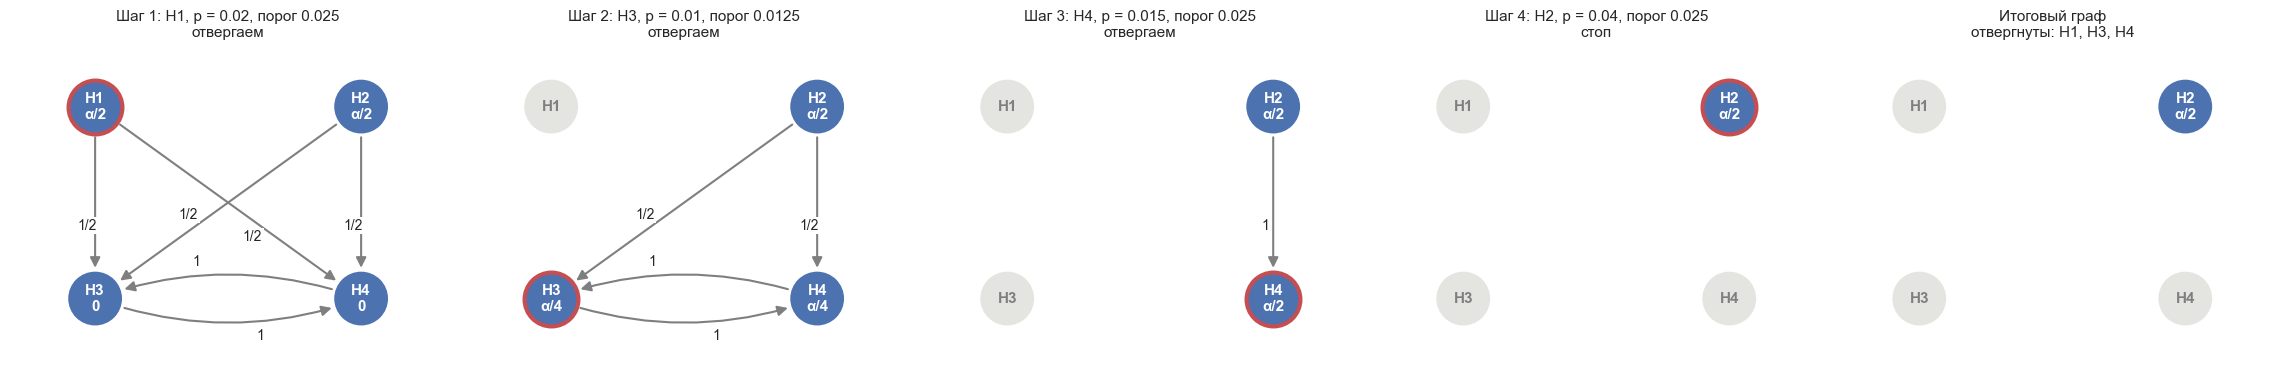

,Проверяем,p,Порог,Решение
Шаг,,,,
1,H1,0.020,0.0250,отвергаем
2,H3,0.010,0.0125,отвергаем
3,H4,0.015,0.0250,отвергаем
4,H2,0.040,0.0250,стоп


In [13]:
p_vals = np.array([0.02, 0.04, 0.01, 0.015])

show_procedure(gate_weights, gate_G, p_vals, alpha, pos=gate_pos)

#### Гейткипинг с ε-рёбрами

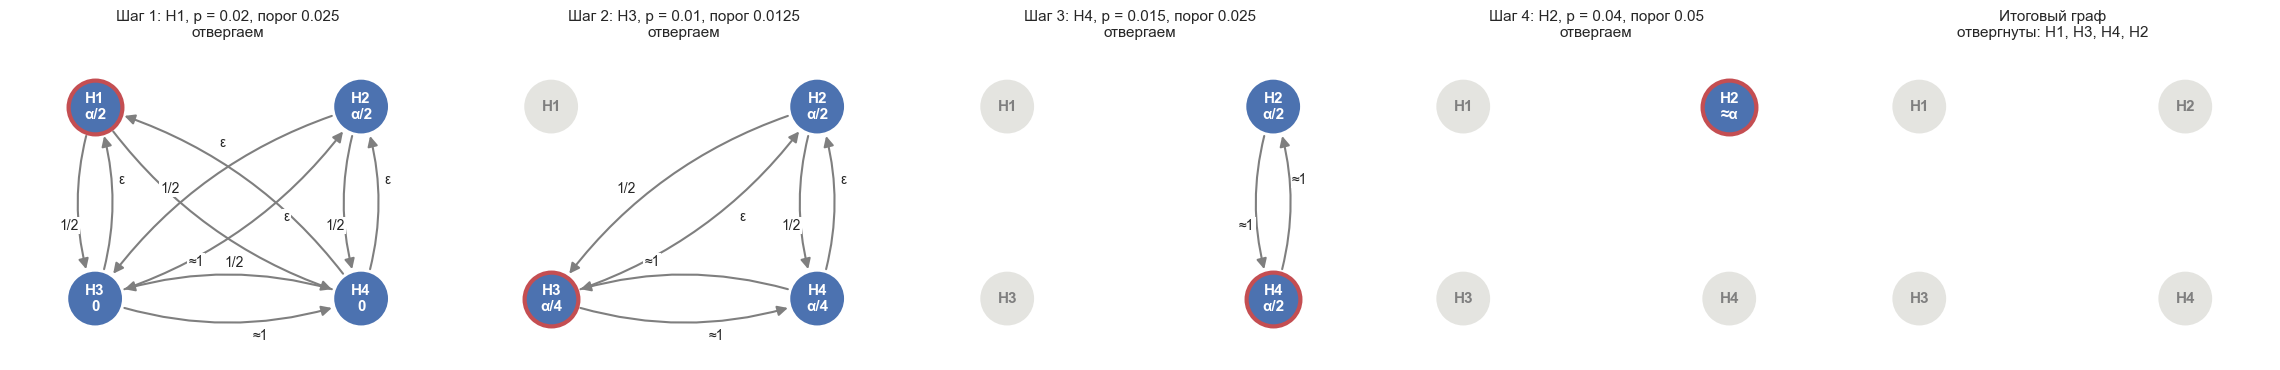

,Проверяем,p,Порог,Решение
Шаг,,,,
1,H1,0.020,0.0250,отвергаем
2,H3,0.010,0.0125,отвергаем
3,H4,0.015,0.0250,отвергаем
4,H2,0.040,0.0500,отвергаем


In [14]:
epsilon = 1e-6
gate_G_eps = np.array([[0, 0, 0.5, 0.5],
                       [0, 0, 0.5, 0.5],
                       [epsilon, epsilon, 0, 1 - 2 * epsilon],
                       [epsilon, epsilon, 1 - 2 * epsilon, 0]])

show_procedure(gate_weights, gate_G_eps, p_vals, alpha, pos=gate_pos)

**Попробуйте сами.** Выберите схему и подвигайте p-значения. Ползунок «Шаг» показывает, как уровень значимости перетекает по графу. Сравните обычный гейткипинг с ε-рёбрами: при каких p-значениях они дают разный результат?

In [15]:
SCHEMES = {
    'Бонферрони': (np.full(4, 0.25), np.zeros((4, 4))),
    'Холм': (np.full(4, 0.25), (np.ones((4, 4)) - np.eye(4)) / 3),
    'Гейткипинг': (gate_weights, gate_G),
    'Гейткипинг с ε-рёбрами': (gate_weights, gate_G_eps),
    'Фиксированная последовательность': (np.array([1.0, 0, 0, 0]), np.array([[0, 1, 0, 0], [0, 0, 1, 0], [0, 0, 0, 1], [0, 0, 0, 0]])),
}


def graph_demo(scheme: str = 'Гейткипинг', p1: float = 0.02, p2: float = 0.04, p3: float = 0.01, p4: float = 0.015, step: int = 1) -> None:
    """Показывает состояние графа на выбранном шаге алгоритма."""
    weights, G = SCHEMES[scheme]
    pvalues = np.array([p1, p2, p3, p4])
    labels = ['H1', 'H2', 'H3', 'H4']
    rejected, final_weights, final_G, _, history = run_steps(weights, G, pvalues, 0.05, range(4))

    fig, ax = plt.subplots(figsize=(8, 4.8))
    if step <= len(history):
        current = history[step - 1]
        j = current['tested']
        removed = tuple(i for i in range(4) if i not in current['active'])
        draw_graph(ax, current['weights'], current['G'], labels, gate_pos, removed, tested=j)
        verdict = 'отвергаем' if current['rejected'] else 'стоп'
        ax.set_title(f"Шаг {step}: {labels[j]}, p = {pvalues[j]:.4f}, порог {current['weights'][j] * 0.05:.4f}, {verdict}")
    else:
        draw_graph(ax, final_weights, final_G, labels, gate_pos, tuple(rejected))
        ax.set_title('Итог: отвергнуты ' + (', '.join(labels[i] for i in rejected) or 'ничего'))
    plt.show()


slider = dict(min=0.001, max=0.1, step=0.001, readout_format='.3f')
interact(graph_demo,
         scheme=Dropdown(options=list(SCHEMES), value='Гейткипинг', description='Схема'),
         p1=FloatSlider(value=0.02, description='p1', **slider),
         p2=FloatSlider(value=0.04, description='p2', **slider),
         p3=FloatSlider(value=0.01, description='p3', **slider),
         p4=FloatSlider(value=0.015, description='p4', **slider),
         step=IntSlider(value=1, min=1, max=5, description='Шаг'));

## Расширения для обобщённых метрик ошибок

### Контроль k-FWER

В предыдущих разделах мы рассматривали строгий контроль FWER — вероятности хотя бы одной ложной находки. Однако в разведочных A/B-тестах, при анализе многих вторичных метрик или в исследованиях безопасности допустимо ослабить контроль, чтобы повысить мощность. Для этого используют **обобщённые метрики ошибок**. Первая из них — **k-FWER** (generalised familywise error rate), определяемая как

$$
k\text{-FWER} = P(V \ge k),
$$

где $V$ — число ложных отклонений, а $k \ge 1$ — заранее заданное целое число. При $k=1$ получаем обычный FWER; при $k=2$ допускаем одну ложную находку без нарушения контроля; при $k=3$ — две и т.д.

Контроль k-FWER означает, что вероятность допустить не менее $k$ ложных отклонений не превышает $\alpha$. **Обобщенная процедура Бонферрони** позволяет контролировать k-FWER: отклонять любые $H_i$, для которых $p_i ≤ k\alpha/m$. Предполагая известные положительные веса $w_i$, которые удовлетворяют $\sum^{m}_{i= 1} w_{i} = 1$, Романо и Вольф (Romano & Wolf, 2010) представили **взвешенную обобщенную процедуру Бонферрони**: отклонить любой $H_i$, для которого $p_i ≤ w_i k\alpha$. Если $w_i = 1/m$ для всех $i$, то это эквивалентно невзвешенной версии. Чтобы расширить графический подход на k-FWER, возникает соблазн просто заменить $\alpha$ на $k\alpha$, по аналогии с обобщённой поправкой Бонферрони. Однако в общем случае это не контролирует k-FWER при $k > 1$. Например, для графа Холма такая замена даёт пошаговую процедуру с порогами $k\alpha / (m+1-i)$, а это слишком мягко (Lehmann & Romano, 2005).

Статья Robertson et al. (2020) предлагает два способа адаптировать графический подход для контроля k-FWER: **дополненный (augmented)** и **обобщённый (generalised)**. Мы начнём с более простого и надёжного — дополненного.

#### Дополненный подход

Идея дополненной процедуры чрезвычайно естественна: **сначала выполнить обычный FWER-тест, а затем «добрать» до $k-1$ дополнительных отвержений**.

Формально алгоритм выглядит так:

1. Применить обычную графическую процедуру для контроля FWER на уровне $\alpha$.
2. Пусть $I$ — множество оставшихся (неотвергнутых) гипотез. Если $I$ пусто, остановиться.
3. Продолжить шаги обычного алгоритма на оставшемся графе, заменив $\alpha$ на $\delta$, пока не будет сделано до $k-1$ дополнительных отвержений.

**Почему k-FWER под контролем.** Первый этап даёт $P(V_1 \ge 1) \le \alpha$, где $V_1$ — число ложных отвержений на нём. Второй этап добавляет не более $k-1$ отвержений. Значит, событие $V \ge k$ возможно, только если на первом этапе была хотя бы одна ложная находка, и $P(V \ge k) \le P(V_1 \ge 1) \le \alpha$.

Итоговое множество отвергнутых гипотез содержит все гипотезы первого этапа плюс до $k-1$ новых, поэтому процедура отвергает **не меньше** гипотез, чем обычный FWER-тест.

**Роль $\delta$.** Параметр $\delta \ge 0$ определяет, сколько «свободных» отвержений мы используем, и он может быть больше $\alpha$. На втором этапе порог для гипотезы равен $w_i \cdot \delta$, поэтому при большом $\delta$ будут отвергнуты все $k-1$ гипотез, даже с $p$-значениями, близкими к 1, которые скорее всего нулевые. Низкие значения $\delta$ означают, что мы готовы отвергнуть гипотезу только при достаточно веских доказательствах. Контроль k-FWER от выбора $\delta$ не зависит, и он может зависеть от данных. Например, можно увеличивать $\delta$ ровно настолько, чтобы сделать очередное отвержение.

В статье Робертсона и соавторов в кейсах используется $\delta = 1$.

#### Обобщённый подход

Альтернативный подход — модифицировать сами пороги внутри алгоритма, чтобы с самого начала допускать до $k-1$ ложных отклонений. Это **обобщённая процедура**.

Формально алгоритм выглядит так:

1. **Инициализация:** $I = M$ (множество всех гипотез).
2. **Первый шаг:** отвергнуть любую гипотезу $H_i$, $i \in I$, для которой $p_i \le w_i(I)\, k\alpha$.
3. Пусть $R$ — множество отвергнутых на этом шаге гипотез. Если $|R| < k$ или $|R| = |I|$, остановиться. Иначе обновить $I \leftarrow I \setminus R$.
4. **Последующие шаги:** для оставшихся гипотез $i \in I$ отвергнуть $H_i$, если
   $$
   p_i \le \min_{J \subseteq R,\ |J| = k-1} \bigl\{ w_i(I \cup J) \bigr\}\, k\alpha.
   $$
   Если таких гипотез нет, остановиться. Иначе пусть $R'$ — множество отвергнутых на этом шаге гипотез.
5. Обновить множества: $I \leftarrow I \setminus R'$, $R \leftarrow R \cup R'$.
6. Если $|I| \ge 1$, вернуться к шагу 4.

Суть шага 4: среди уже отвергнутых гипотез может быть до $k-1$ истинных нулевых. Мы не знаем, какие именно, поэтому перебираем все подмножества $J$ размера $k-1$ среди отвергнутых и считаем вес $w_i(I \cup J)$ в графе, куда эти гипотезы возвращены. Минимальный из этих весов даёт самый осторожный порог.

При $k = 1$ подмножество $J$ пусто, и алгоритм совпадает с обычной графической процедурой.

У обобщённой процедуры есть существенный недостаток: **проблема доноров**. Донорами гипотезы называют гипотезы, которые передают ей свой уровень при отвержении. Если у гипотезы $H_j$ **меньше $k$ доноров**, её начальный вес никогда не вырастет: в подмножестве $J$ всегда найдётся набор, содержащий всех доноров, и в графе с ними вес останется начальным. Гипотеза с нулевым начальным весом при этом никогда не будет отвергнута, даже с очень маленьким $p$-значением. В иерархических графах (гейткипинг, фиксированная последовательность) доноров обычно один или два, поэтому обобщённая процедура может отвергнуть даже меньше гипотез, чем обычный FWER-тест.

#### Сравнение мощности

Литература даёт смешанную картину (Romano & Wolf, 2007; Dudoit et al., 2004), и результат зависит от числа гипотез:

* **Большое число гипотез.** При $m = 400$ и $k = 10$ обобщённая процедура Холма может сделать вдвое больше отвержений, чем дополненная: дополненная добавляет не более $k-1$ гипотез к обычному FWER-тесту.
* **Небольшое число гипотез.** При $m = 50$ и $k = 3$ дополненная процедура почти всегда отвергает больше.

В клинических исследованиях и в A/B-тестах обычно число гипотез невелико, а структура иерархическая, поэтому авторы рекомендуют дополненный подход. Позже мы проверим это на реальных p-значениях в кейсе с фармакодинамическим исследованием.

### Контроль FDP и асимптотический контроль FDR

Контроль k-FWER, который мы только что изучили, позволяет ограничить **число** ложных отклонений. Но в исследовательских задачах с большим числом гипотез часто важнее контролировать не абсолютное число, а **долю** ложных находок среди всех сделанных утверждений. Представьте, что в масштабном A/B-тесте вы проверили 200 метрик и отвергли 50 из них. Если вы использовали контроль 5-FWER, то с вероятностью не ниже $1 - \alpha$ ложных среди 50 не более 4. Но если вы не знаете, сколько всего будет отвергнуто, абсолютная цифра даёт мало информации. Гораздо удобнее сказать: «с вероятностью 95% доля ложных отклонений не превышает 10%». Именно это даёт контроль **хвостовой вероятности FDP** (False Discovery Proportion).

Формально, пусть $V$ — число ложных отклонений, $R$ — общее число отвергнутых гипотез. Тогда

$$
\mathrm{FDP} = \frac{V}{\max(R,1)} .
$$

Мы хотим гарантировать, что

$$
P(\mathrm{FDP} > \gamma) \le \alpha,
$$

где $\gamma \in [0,1)$ — максимально допустимая доля ложных находок. При $\gamma=0$ мы возвращаемся к обычному FWER.

С контролем FDP тесно связан **False Discovery Rate** (FDR) — математическое ожидание FDP. Контроль FDP на уровне $\alpha$ влечёт контроль FDR на уровне $\alpha^* = \alpha(1-\gamma)+\gamma$ (Lehmann & Romano, 2005). Для дополненной процедуры есть и другая граница: асимптотический контроль FDR на уровне $2\alpha$ (van der Laan et al., 2004). Первая граница лучше, если $\gamma < \alpha / (1-\alpha)$.

Статья предлагает два способа контролировать FDP в рамках графического подхода: дополненный и обобщённый. Их логика полностью аналогична случаю k-FWER, только вместо числа дополнительных отверждений управляют долей.

#### Дополненный подход для FDP

Дополненная процедура для FDP является прямым обобщением дополненной процедуры для k-FWER. Вместо того чтобы добавлять ровно $k-1$ отверждений, мы добавляем до $D$ дополнительных, где $D$ — наибольшее целое число, удовлетворяющее неравенству

$$
\frac{D}{D + |R|} \le \gamma,
$$

и $R$ — множество гипотез, отвергнутых на первом этапе (обычный FWER-тест). Это гарантирует, что итоговая доля дополнительных отверждений не превысит $\gamma$.

Формально алгоритм выглядит так:

1. Применить обычную Bonferroni-based графическую FWER-процедуру на уровне $\alpha$. Получить множество отвергнутых гипотез $R$.
2. Пусть $I$ — множество оставшихся (неотвергнутых) гипотез. Если $I$ пусто, остановиться.
3. Вычислить $D$ — наибольшее целое, для которого $\frac{D}{D+|R|} \le \gamma$. Если $D=0$, остановиться.
4. Продолжить шаги обычного алгоритма на оставшемся графе, заменив $\alpha$ на $\delta$, пока не будет сделано **до $D$ дополнительных отвержений**.

После выполнения этого алгоритма итоговое множество отвергнутых гипотез содержит все $R$ с первого этапа плюс до $D$ дополнительных. Вероятность того, что доля ложных среди них превысит $\gamma$, не больше $\alpha$ (van der Laan et al., 2004).

Если положить $\gamma = (k-1)/(k-1+|R|)$, дополненная FDP-процедура сведётся к дополненной k-FWER процедуре с параметром $k$. Таким образом, FDP-версия является более гибкой: она автоматически адаптирует число дополнительных отверждений к числу уже сделанных, не требуя фиксировать $k$ заранее.

#### Обобщённый подход для FDP

Обобщённая процедура для FDP строится на базе обобщённой процедуры для k-FWER. Идея состоит в том, чтобы последовательно применять процедуру $k_j$-FWER для $k_j = 1, 2, 3, \dots$ до тех пор, пока не выполнится условие, гарантирующее контроль FDP.

Алгоритм следующий:

1. Положим $j=1$, $k_1=1$.
2. Применить обобщённую $k_j$-FWER процедуру и получить множество отвергнутых гипотез $R_j$.
3. Если $|R_j| < k_j / \gamma - 1$, остановиться и отвергнуть все гипотезы, отвергнутые $k_j$-FWER процедурой.
4. Иначе положить $j \leftarrow j+1$, $k_j = k_{j-1}+1$ и вернуться к шагу 2.

Другими словами, мы начинаем с обычного FWER. Если это даёт «слишком много» отвергнутых гипотез относительно порога $1/\gamma - 1$, мы переходим к $k=2$, потом к $k=3$ и так далее, пока число отвергнутых не станет достаточно малым. На каждом шаге используется обобщённая процедура для соответствующего $k$.

Для этого алгоритма доказан только **асимптотический контроль FDP** (Romano & Wolf, 2010), хотя эмпирически он хорошо работает и на конечных выборках. Однако он наследует недостатки обобщённой k-FWER процедуры, включая проблему доноров. В иерархических графах это может дать очень мало отвержений, что мы увидим на кейсах.

#### Сравнение на данных

На том же фармакодинамическом исследовании результаты согласуются с выводами для k-FWER, и мы воспроизведём их в разделе с кейсами. При $\gamma = 0.1$ обе процедуры дают 8 отвержений: здесь $D = 0$. При $\gamma = 0.2$ дополненная процедура отвергает 10 гипотез, обобщённая только 3. При $\gamma = 0.3$ разрыв ещё больше: 11 против 3.

## Методологические расширения графического подхода

До сих пор мы рассматривали классический графический подход, основанный на взвешенных тестах Бонферрони и однократном анализе данных в конце эксперимента. Однако реальные клинические и A/B-исследования часто требуют более сложных дизайнов: промежуточных анализов, сложных логических условий (например, «хотя бы K из N»), или учёта корреляции между тестовыми статистиками. В этом разделе мы познакомимся с тремя важными расширениями, которые делают графический подход ещё более универсальным инструментом.

### Запутанные графы (entangled graphs)

**Мотивация.** В обычном графе уровень передаётся одинаково, откуда бы он ни пришёл: у графа нет памяти. Но иногда логика требует, чтобы путь уровня зависел от его происхождения. Например, условие «отвергнуть хотя бы 6 из 9 первичных гипотез, прежде чем перейти к вторичным» одним обычным графом не изобразить.

**Решение.** Маурер и Бретц (Maurer & Bretz, 2013a) предложили **запутанные графы** (entangled graphs). Идея состоит в том, чтобы построить отдельный граф для каждого нужного отношения, например для каждой комбинации из 6 первичных гипотез, а затем объединить их. Если имеется $L$ графов, каждому приписывается вес $c_l$, причём $\sum c_l = 1$. Алгоритм работает с ними одновременно: при отвержении гипотезы уровень обновляется во всех графах, а локальный уровень гипотезы равен взвешенной сумме её уровней по графам.

**Значение.** Запутанные графы дают графическому подходу память и остаются в рамках замкнутой процедуры тестирования, сохраняя контроль FWER. Весовая стратегия при этом монотонна, поэтому на такие графы переносятся и дополненные, и обобщённые процедуры.

### Групповые последовательные дизайны

**Мотивация.** В клинических испытаниях (а иногда и в некоторых A/B-тестах) данные поступают последовательно, и этически необходимо проводить **промежуточные анализы** (interim analyses) с возможностью досрочной остановки при очевидной эффективности или бесполезности. Каждый такой анализ «тратит» часть общего уровня значимости $\alpha$, и эту трату необходимо планировать заранее с помощью **функции траты $α$** ($α$-spending function), например, границ O'Brien–Fleming или Pocock.

**Решение.** Маурер и Бретц (Maurer & Bretz, 2013b) обобщили графический подход на групповые последовательные дизайны. Основная идея: на каждом промежуточном анализе $t$ для каждого пересечения гипотез $H_I$ вычисляются **номинальные уровни значимости** $\tilde{\alpha}_{i,t}(\kappa_I)$, где $\kappa_I$ — общий уровень, выделенный на это пересечение. Эти номинальные уровни зависят от выбранной функции траты $α$ и от информации, накопленной к моменту $t$. Затем применяется графический алгоритм, который на каждом шаге использует эти номинальные уровни вместо обычных бонферрониевских порогов.

Ключевое условие — **монотонность номинальных уровней** по отношению к общему уровню $\kappa$: $\tilde{\alpha}_{i,t}(\kappa') \ge \tilde{\alpha}_{i,t}(\kappa)$ при $\kappa' > \kappa$. Это выполняется для большинства стандартных функций траты. При соблюдении монотонности весь аппарат замкнутого тестирования и консонантности сохраняется, и можно построить shortcut-процедуру.

**Значение.** Графический подход с групповым последовательным дизайном позволяет контролировать FWER (или k-FWER, FDP) во времени, принимая решения об остановке или продолжении на каждом промежуточном анализе. Это делает его мощным инструментом для планирования и мониторинга клинических испытаний.

### Взвешенные параметрические тесты

**Мотивация.** Все рассмотренные нами процедуры использовали **взвешенный тест Бонферрони** в качестве локального теста для каждого пересечения гипотез. Бонферрони корректен при **любых** зависимостях между $p$-значениями, но за это приходится платить консервативностью: реальный уровень отвержения часто существенно ниже номинального $\alpha$, особенно при сильной положительной корреляции между тестовыми статистиками. В A/B-тестах, где метрики часто сильно скоррелированы (например, различные показатели вовлечённости), это приводит к потере мощности.

**Решение.** Если совместное распределение тестовых статистик известно (например, многомерное нормальное), можно заменить взвешенный Бонферрони на **взвешенный min-p тест** (Westfall & Young, 1993; Westfall et al., 1998). Для пересечения $H_I$ с весами $w_i(I)$ этот тест отвергает $H_I$, если существует $i \in I$ такое, что

$$
p_i \le c_I \cdot w_i(I)\,\alpha,
$$

где константа $c_I \ge 1$ подбирается так, чтобы

$$
P_{H_I}\left( \bigcup_{i \in I} \{p_i \le c_I \, w_i(I)\,\alpha\} \right) \le \alpha.
$$

Благодаря учёту корреляций, $c_I$ может быть значительно больше 1, что повышает мощность.

Для того чтобы такой параметрический тест можно было встроить в графический shortcut, необходимо, чтобы выполнялось **условие монотонности** с поправкой на $c_I$:

$$
c_{J}\, w_i(J) \ge c_{I}\, w_i(I) \quad \text{для всех } J \subseteq I,\; i \in J.
$$

На практике это условие часто нарушается (Bretz et al., 2011). Тогда иногда можно изменить схему весов так, чтобы оно выполнялось (Bretz et al., 2011; Xi et al., 2017). Если известна только часть совместного распределения, для $c_I$ используют консервативные верхние границы.

**Значение.** Использование параметрических тестов в графическом подходе позволяет существенно повысить мощность при сильной корреляции метрик, что типично для онлайн-экспериментов. Однако это требует осторожной верификации монотонности и, возможно, модификации весов. В стандартных пакетах (например, gMCP в R) поддержка параметрических тестов уже реализована.

## Примеры применения графических процедур

В этой части лекции мы посмотрим применение изученных графических методов к трём реальным клиническим исследованиям. Каждый кейс иллюстрирует различные аспекты: иерархические семейства гипотез, гейткипинг «K из N», сравнение дополненных и обобщённых процедур.

### Фармакодинамическое исследование

**Контекст исследования**

Это разведочное (exploratory) клиническое исследование фармакодинамики препарата, воздействующего на GABA-A рецепторы в головном мозге (Ferber et al., 2011). Эффект измерялся с помощью количественной электроэнцефалографии (qEEG). Три дозы препарата (0.25 мг, 0.5 мг и 1 мг) сравнивались с плацебо. Запись qEEG в течение первых 15 минут после введения была разбита на пять временных интервалов по 3 минуты. Каждый контраст «доза-время» образует нулевую гипотезу $T_iD_j$: изменение от исходного уровня под дозой $j$ во временном интервале $i$ не отличается от плацебо. Всего $3 \times 5 = 15$ гипотез.

Исходные $p$-значения, полученные из линейной модели со смешанными эффектами:

| Доза | T1 | T2 | T3 | T4 | T5 |
| :--- | ---: | ---: | ---: | ---: | ---: |
| D1 | 0.7808 | 0.0600 | 0.0137 | 0.0724 | 0.0162 |
| D2 | 0.9433 | 0.0053 | 6.5e-06 | 2.8e-06 | 9.1e-08 |
| D3 | 0.9993 | 1.0e-05 | 1.7e-11 | 4.2e-12 | 8.1e-13 |

Видна сильная значимость высоких доз в поздние временные точки и почти полное отсутствие эффекта в первом интервале.

**Иерархическая стратегия тестирования**

Исследователи определили естественный порядок проверки: от более высоких доз и более поздних временных точек к более низким дозам и ранним точкам, отражая ожидаемую силу эффекта.

В оригинальной публикации $T_4D_3$ и $T_5D_2$ имели нулевые начальные веса, а единственным донором для них была $T_5D_3$. Обобщённая процедура при $k=2$ тогда не смогла бы отвергнуть ничего, кроме $T_5D_3$. Поэтому в статье рассмотрены **два варианта начальных весов**:

1. **Модифицированные веса:** трём гипотезам $T_4D_3$, $T_5D_2$, $T_5D_3$ присвоен вес $1/3$, остальным 12 гипотезам 0.
2. **Равные веса:** каждая из 15 гипотез получает вес $1/15$. Этот вариант проверяет, как начальное распределение влияет на обобщённые процедуры.

Построим граф с модифицированными весами. Все рёбра здесь имеют вес $1/2$.

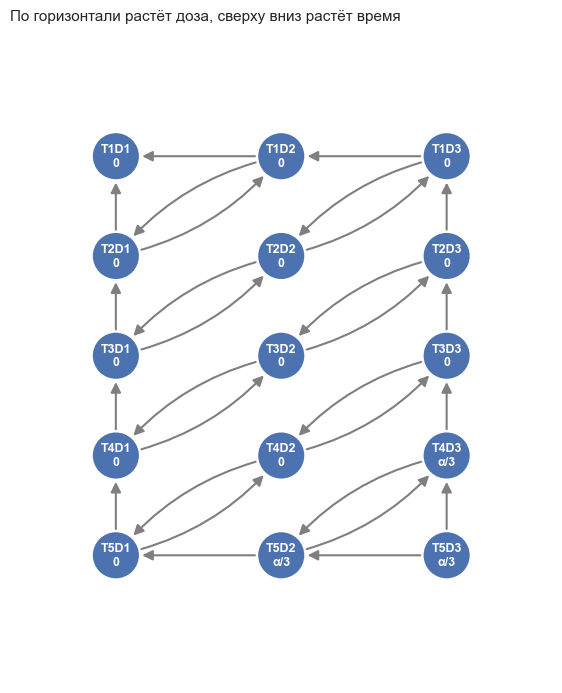

In [16]:
pd_names = [f'T{i}D{j}' for i in range(1, 6) for j in range(1, 4)]
pd_index = {name: i for i, name in enumerate(pd_names)}
pd_p = np.array([0.7808, 0.9433, 0.9993,
                 0.0600, 0.0053, 1.0e-5,
                 0.0137, 6.5e-6, 1.7e-11,
                 0.0724, 2.8e-6, 4.2e-12,
                 0.0162, 9.1e-8, 8.1e-13])

pd_edges = [(f'T{i}D{d}', f'T{i - 1}D{d}') for i in range(2, 6) for d in (1, 3)]                  # время
pd_edges += [('T5D3', 'T5D2'), ('T5D2', 'T5D1'), ('T1D3', 'T1D2'), ('T1D2', 'T1D1')]              # доза
for i in range(1, 5):                                                                            # диагонали
    pd_edges += [(f'T{i + 1}D1', f'T{i}D2'), (f'T{i}D2', f'T{i + 1}D1'),
                 (f'T{i + 1}D2', f'T{i}D3'), (f'T{i}D3', f'T{i + 1}D2')]

pd_G = np.zeros((15, 15))
for source, target in pd_edges:
    pd_G[pd_index[source], pd_index[target]] = 0.5

weights_modified = np.zeros(15)
weights_modified[[pd_index[name] for name in ('T4D3', 'T5D2', 'T5D3')]] = 1 / 3
weights_equal = np.full(15, 1 / 15)

pd_pos = [[int(name[3]) * 1.6, 6 - int(name[1])] for name in pd_names]
fig, ax = plt.subplots(figsize=(7, 8.5))
draw_graph(ax, weights_modified, pd_G, pd_names, pos=pd_pos, node_size=1100, edge_labels=False, font_size=9)
ax.set_title('По горизонтали растёт доза, сверху вниз растёт время', loc='left', fontsize=11)
plt.show()

**Применение графических процедур**

Применим к этим данным все рассмотренные процедуры с $\alpha = 0.05$ и $\delta = 1$. Результаты воспроизводят таблицы 2 и 3 из статьи Robertson et al. (2020).

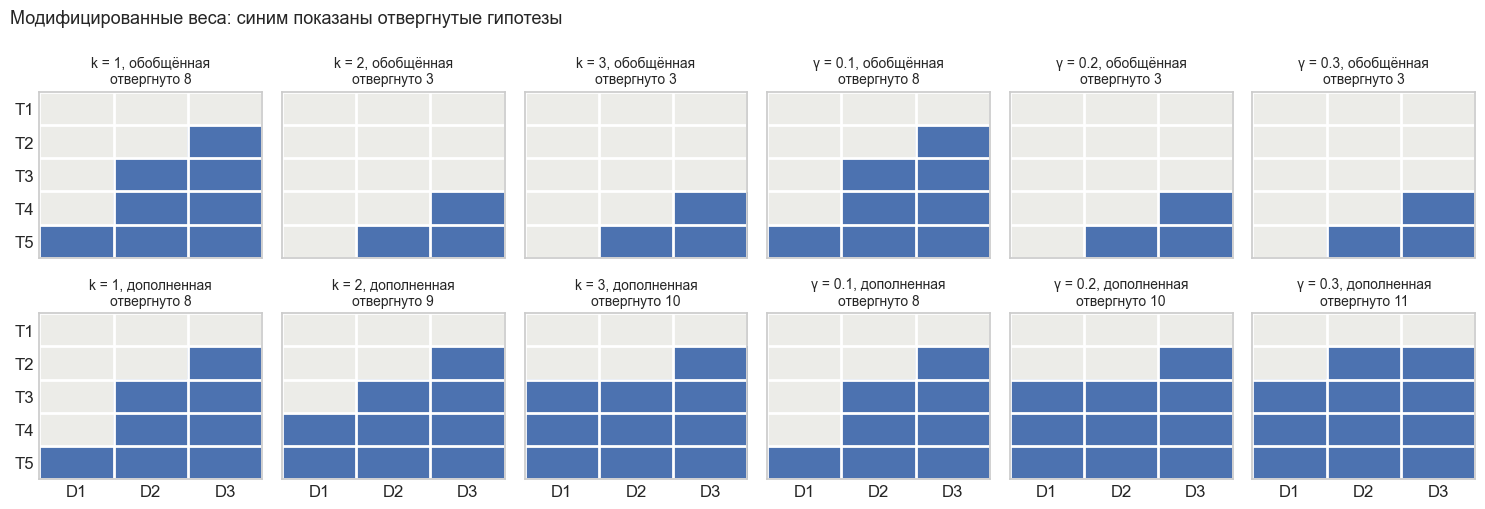

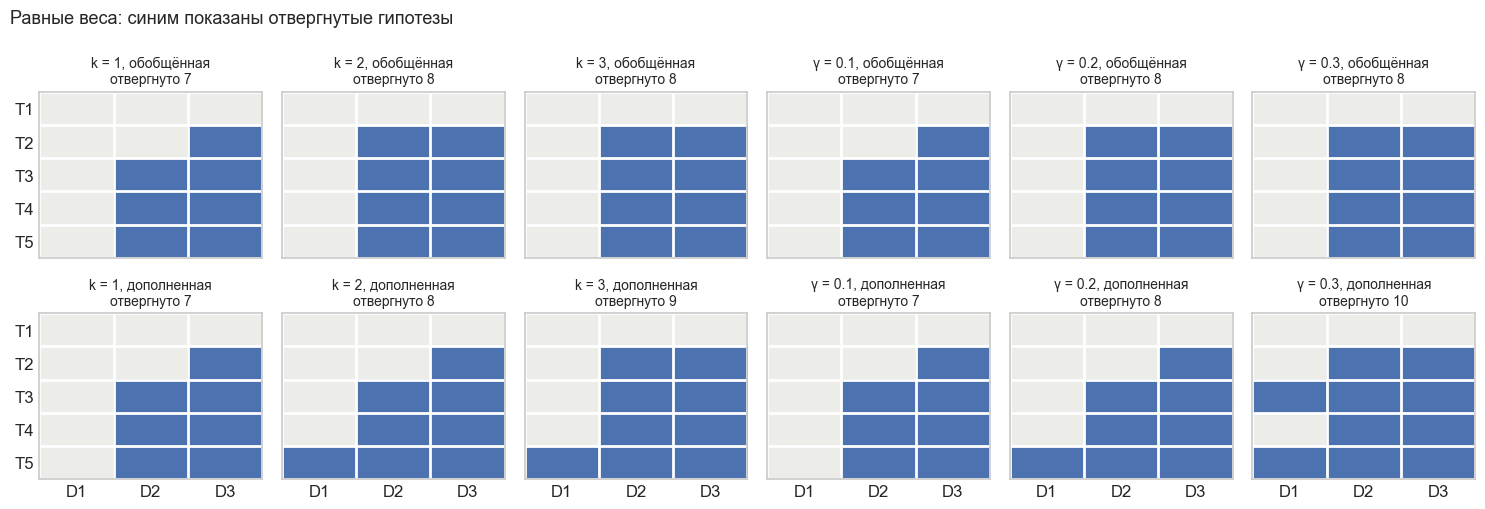

In [17]:
def compare_procedures(weights: np.ndarray) -> dict:
    """Запускает все процедуры на данных фармакодинамического исследования."""
    results = {}
    for k in (1, 2, 3):
        results[f'k = {k}, обобщённая'] = generalised_kfwer(weights, pd_G, pd_p, alpha, k)
        results[f'k = {k}, дополненная'] = augmented_test(weights, pd_G, pd_p, alpha, k=k)
    for gamma in (0.1, 0.2, 0.3):
        results[f'γ = {gamma}, обобщённая'] = generalised_fdp(weights, pd_G, pd_p, alpha, gamma)
        results[f'γ = {gamma}, дополненная'] = augmented_test(weights, pd_G, pd_p, alpha, gamma=gamma)
    return results


def plot_rejections(results: dict, title: str) -> None:
    """Показывает отвергнутые гипотезы на сетке доза-время для каждой процедуры."""
    fig, axes = plt.subplots(2, 6, figsize=(15, 5.2), sharex=True, sharey=True)
    for ax, (name, rejected) in zip(axes.ravel(order='F'), results.items()):
        matrix = np.zeros((5, 3))
        matrix[[index // 3 for index in rejected], [index % 3 for index in rejected]] = 1
        ax.imshow(matrix, cmap=plt.cm.colors.ListedColormap(['#ECECE8', BLUE]), vmin=0, vmax=1, aspect='auto')
        ax.set_title(f'{name}\nотвергнуто {len(rejected)}', fontsize=10)
        ax.set_xticks(range(3), ['D1', 'D2', 'D3'])
        ax.set_yticks(range(5), [f'T{i}' for i in range(1, 6)])
        ax.grid(False)
        ax.set_xticks(np.arange(-0.5, 3), minor=True)
        ax.set_yticks(np.arange(-0.5, 5), minor=True)
        ax.grid(which='minor', color='white', linewidth=2)
        ax.tick_params(which='both', length=0)
    fig.suptitle(title, x=0.01, ha='left', fontsize=13)
    plt.tight_layout()
    plt.show()


plot_rejections(compare_procedures(weights_modified), 'Модифицированные веса: синим показаны отвергнутые гипотезы')
plot_rejections(compare_procedures(weights_equal), 'Равные веса: синим показаны отвергнутые гипотезы')

**Обсуждение результатов**

1. **Обычный FWER-тест ($k=1$, $\gamma=0.1$).** Отвергается 7–8 гипотез, причём с модифицированными весами на одну больше: $T_5D_1$. Обе процедуры здесь совпадают.

2. **Поведение обобщённой процедуры.** При модифицированных весах она «ломается» уже при $k=2$: отвергаются только три гипотезы с ненулевыми начальными весами. При $k=3$ причина прямая: у всех гипотез меньше трёх доноров. При $k=2$ почти у всех гипотез доноров два, но уровень всё равно не распространяется по графу. При равных весах процедура работает лучше, но перестаёт расти: при $k=3$ она не даёт новых отвержений.

3. **Преимущество дополненной процедуры.** При модифицированных весах она отвергает 9–11 гипотез. Интересно, что новых отвержений ровно столько, сколько разрешено ($k-1$ или $D$): при $\delta = 1$ порог мягкий, и лимит расходуется полностью. При равных весах и $k=2$ или $\gamma=0.2$ обе процедуры отвергают по 8 гипотез, но разные наборы. Дополненная выигрывает при $k=3$ и $\gamma=0.3$.

4. **Роль $\delta$.** При $\delta = 1$ дополненная процедура использует лимит почти без ограничений. Обратите внимание, что с ростом $k$ она добавляет гипотезы с $p$-значениями вроде 0.07. Контроль k-FWER при этом сохраняется, но отдельные дополнительные находки не имеют сильных доказательств. Контроль ослаблен осознанно, и это разумно только в разведочном исследовании.

**Попробуйте сами.** Выясните, как $k$ и $\delta$ влияют на дополненную процедуру при модифицированных весах. При маленьком $\delta$ разрешённые отвержения не используются полностью: это и есть способ не отвергать гипотезы со слабыми доказательствами.

In [18]:
def augmented_demo(k: int = 3, delta: float = 1.0) -> None:
    """Показывает, какие гипотезы дополненная процедура добавляет к FWER-тесту."""
    base = graph_test(weights_modified, pd_G, pd_p, alpha)
    full = augmented_test(weights_modified, pd_G, pd_p, alpha, k=k, delta=delta)
    matrix = np.zeros((5, 3))
    matrix[[index // 3 for index in full], [index % 3 for index in full]] = 2
    matrix[[index // 3 for index in base], [index % 3 for index in base]] = 1

    fig, ax = plt.subplots(figsize=(5.5, 4.8))
    ax.imshow(matrix, cmap=plt.cm.colors.ListedColormap(['#ECECE8', BLUE, '#DD8452']), vmin=0, vmax=2)
    for row in range(5):
        for column in range(3):
            ax.text(column, row, f'{pd_p[row * 3 + column]:.2g}', ha='center', va='center', color='white' if matrix[row, column] else 'black', fontsize=9)
    ax.set_xticks(range(3), ['D1', 'D2', 'D3'])
    ax.set_yticks(range(5), [f'T{i}' for i in range(1, 6)])
    ax.grid(False)
    ax.set_title(f'Синие: FWER-тест, {len(base)}. Оранжевые: добавлены, {len(full) - len(base)}', loc='left', fontsize=11)
    plt.tight_layout()
    plt.show()


interact(augmented_demo,
         k=IntSlider(value=3, min=1, max=6, description='k'),
         delta=FloatSlider(value=1.0, min=0.05, max=2, step=0.05, description='δ'));

**Заключение по кейсу**

Фармакодинамическое исследование наглядно демонстрирует, что:

- Графический подход легко адаптируется к контролю k-FWER и FDP.
- Дополненная процедура предпочтительнее в иерархических структурах, так как она способна передавать уровень гипотезам с малым числом доноров и всегда даёт не меньше отвержений, чем обычный FWER-тест.
- Выбор начальных весов может влиять на результаты обобщённых процедур; равномерное распределение улучшает их работу, но не устраняет принципиальных ограничений.

### Исследование Pre-RELAX-AHF

**Контекст исследования**

Pre-RELAX-AHF (Preliminary study of RELAXin in Acute Heart Failure) — это многоцентровое рандомизированное плацебо-контролируемое исследование фазы IIb по изучению релаксина у пациентов с острой сердечной недостаточностью. Три дозы препарата (10, 30 и 100 мкг/кг/день) сравнивались с плацебо. Основной целью было получение первого доказательства концепции (proof-of-concept) и выбор дозы для последующей фазы III. В данном кейсе (следуя анализу Davison et al., 2011 и Robertson et al., 2020) мы фокусируемся только на дозе **30 мкг/кг/день**, которая показала эффект на 6 конечных точках из 9 при одностороннем $\alpha = 0.1$ без поправок.

Исходно в исследовании оценивалось множество конечных точек. Для нашего анализа выбраны **9 бинарных или непрерывных конечных точек эффективности** (например, изменение давления заклинивания лёгочных капилляров, диурез, изменение креатинина и т.д.). По каждой из них формулируется нулевая гипотеза $H_i:\; \theta_i \le 0$ (нет превосходства релаксина над плацебо), $i = 1,\dots,9$. Авторы статьи дополняют дизайн гипотетическим вторичным семейством: для простоты это одна **составная гипотеза безопасности** $H_{10}$, которая проверяется, только если продемонстрирована эффективность по большинству первичных конечных точек.

Средние и стандартные отклонения для моделирования взяты из работы Delorme et al. (2016) и приведены в Приложении C статьи. Здесь мы не будем повторять симуляцию и воспользуемся её результатами.

**Иерархическая стратегия: гейткипинг «6 из 9»**

В рассматриваемом дизайне успех означает эффективность **хотя бы по 6 из 9 первичных конечных точек**:

$$
\text{Успех} \iff \text{отвергнуты } \ge 6 \text{ гипотез из } \mathcal{F}_1 = \{H_1,\dots,H_9\}.
$$

Только в случае успеха разрешается тестировать вторичную гипотезу $H_{10}$. Такой гейткипинг «K из N» ($K=6$, $N=9$) невозможно представить одним обычным графом.

Для реализации этой логики применяют **запутанные графы**: строят отдельный граф с процедурой Холма для каждого подмножества из 6 первичных гипотез и объединяют их с весами $1 / \binom{9}{6} = 1/84$. Если все 6 гипотез подмножества отвергнуты, его уровень переходит к $H_{10}$.

Это эквивалентно динамическим весам. Обозначим через $|I|$ число ещё не отвергнутых первичных гипотез:

| $\lvert I \rvert$ | Вес каждой гипотезы из $\mathcal{F}_1$ | Вес $H_{10}$ |
| :---: | :---: | :---: |
| > 3 | $1 / \lvert I \rvert$ | 0 |
| 3 | 83/252 | 1/84 |
| 2 | 11/24 | 1/12 |
| 1 | 2/3 | 1/3 |
| 0 | – | 1 |

Пока отвергнуто меньше 6 гипотез, это обычный Холм на первичных гипотезах. Как только отвергнуто 6, $H_{10}$ получает положительный вес, а остальные первичные продолжают проверяться.

**Применение графических процедур и симуляция мощности**

Авторы провели симуляцию, чтобы сравнить мощность процедур:

* средние и стандартные отклонения взяты из Delorme et al. (2016);
* статистики имеют многомерное нормальное распределение с общей корреляцией $\rho$;
* статистика для $H_{10}$ нормальна со средним 3 и дисперсией 1 и не зависит от первичных;
* $\alpha = 0.1$, для дополненных процедур $\delta = 1$;
* 10 000 повторений.

Маргинальная мощность в процентах (таблица 5 статьи). $H_9$ — истинная нулевая гипотеза, поэтому в её столбце стоит вероятность ошибочного отвержения:

| Процедура | H1 | H2 | H3 | H4 | H5 | H6 | H7 | H8 | H9 | H10 |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| k = 1, обе | 95 | 89 | 72 | 78 | 85 | 100 | 100 | 62 | 6 | 64 |
| k = 2, обобщённая | 97 | 93 | 79 | 84 | 90 | 100 | 100 | 70 | 9 | 60 |
| k = 2, дополненная | 99 | 97 | 90 | 92 | 95 | 100 | 100 | 87 | 65 | 84 |
| k = 3, обобщённая | 98 | 95 | 81 | 86 | 92 | 100 | 100 | 73 | 10 | 42 |
| k = 3, дополненная | 100 | 99 | 96 | 97 | 98 | 100 | 100 | 95 | 87 | 95 |
| γ = 0.1, обобщённая | 95 | 89 | 72 | 78 | 85 | 100 | 100 | 62 | 8 | 61 |
| γ = 0.1, дополненная | 95 | 89 | 72 | 78 | 85 | 100 | 100 | 63 | 38 | 65 |
| γ = 0.2, обобщённая | 95 | 92 | 78 | 83 | 89 | 100 | 100 | 70 | 9 | 50 |
| γ = 0.2, дополненная | 96 | 93 | 82 | 86 | 90 | 100 | 100 | 77 | 52 | 73 |
| γ = 0.3, обобщённая | 96 | 93 | 80 | 85 | 90 | 100 | 100 | 72 | 10 | 6 |
| γ = 0.3, дополненная | 97 | 94 | 86 | 88 | 92 | 100 | 100 | 83 | 58 | 83 |

**Обсуждение результатов**

1. **Мощность для реальных эффектов.** Мощность при обычном FWER составляет от 62% до 100%. Переход к $k = 2$ у дополненной процедуры поднимает самую слабую гипотезу $H_8$ с 62% до 87%, а $k = 3$ до 95%. Обобщённая процедура прибавляет заметно меньше: 70% и 73%.

2. **Цена этого прироста.** $H_9$ — истинная нулевая гипотеза. При $k=1$ она отвергается в 6% случаев, но у дополненной процедуры при $k=2$ уже в 65% случаев, а при $k=3$ в 87%. Это не нарушение контроля: k-FWER ограничивает вероятность $k$ и более ложных отвержений, а не ошибку отдельной гипотезы. Здесь нулевая гипотеза только одна, поэтому при $k \ge 2$ событие $V \ge k$ вообще невозможно. Дополненная процедура с $\delta = 1$ просто направляет разрешённые отвержения на следующие по порядку гипотезы, и $H_9$ часто оказывается среди них. У обобщённой процедуры эта вероятность не превышает номинальные 10%.

3. **Мощность для вторичной гипотезы $H_{10}$.** Она имеет нулевой начальный вес и открывается только после успеха 6 из 9. При $k=1$ мощность равна 64%. У обобщённой процедуры с ростом $k$ она **падает** до 60% и 42%, а при $\gamma=0.3$ до 6%: это проявление проблемы доноров. Дополненная процедура, напротив, повышает её до 84% и 95%.

4. **Сравнение процедур.** Дополненная процедура ни в одной строке не уступает обобщённой по мощности, но расплачивается вероятностью ложного отвержения отдельной нулевой гипотезы.

**Заключение по кейсу**

Исследование Pre-RELAX-AHF иллюстрирует несколько важных аспектов:

- **Запутанные графы** позволяют реализовать сложные логические условия типа «K из N», не покидая рамок графического подхода и сохраняя строгий контроль ошибок.
- Даже в таких комплексных дизайнах **дополненные процедуры** обеспечивают прирост мощности по сравнению с обычным FWER и превосходят обобщённые процедуры, которые страдают от структурных ограничений графа.
- Разведочный характер исследования оправдывает использование k-FWER или FDP, но нужно понимать цену: отдельная нулевая гипотеза может часто попадать в «разрешённые» отвержения. Поэтому дополнительные находки стоит рассматривать как кандидатов на проверку, а не как доказанные эффекты.

### Исследование ATMOSPHERE

**Контекст исследования**

ATMOSPHERE (Aliskiren Trial to Minimize Outcomes in Patients with Heart failure) — подтверждающее клиническое исследование у пациентов с сердечной недостаточностью. В нём сравнивались три терапии: **A** — монотерапия алискиреном, **E** — монотерапия эналаприлом, **C** — комбинация алискирена и эналаприла.

Гипотезы образуют три первичные проверки и два вторичных семейства:

* $H_1$: комбинация C не превосходит E (non-superiority);
* $H_2$: A уступает E (inferiority, проверка не меньшей эффективности);
* $H_3$: A не превосходит E (non-superiority);
* $\mathcal{H}_4 = \{H_{41}, H_{42}\}$: две вторичные конечные точки для сравнения C и E;
* $\mathcal{H}_5 = \{H_{51}, H_{52}\}$: две вторичные конечные точки для сравнения A и E.

На графе ниже семейства раскрыты в отдельные вершины. Внутри семейства работает процедура Холма, а уровень выходит из семейства, только когда отвергнуты **все** его гипотезы. Это реализовано $\varepsilon$-рёбрами: $H_{41}, H_{42}$ передают уровень к $H_2$, а $H_{51}, H_{52}$ к $H_1$.

Используем гипотетические p-значения из Maurer & Bretz (2014) при общем одностороннем $\alpha = 0.025$:

$$
p_1 = 0.1,\quad p_2 = 0.007,\quad p_3 = 0.05,\quad p_{41}=0.0015,\quad p_{42}=0.04,\quad p_{51}=0.0031,\quad p_{52}=0.001
$$

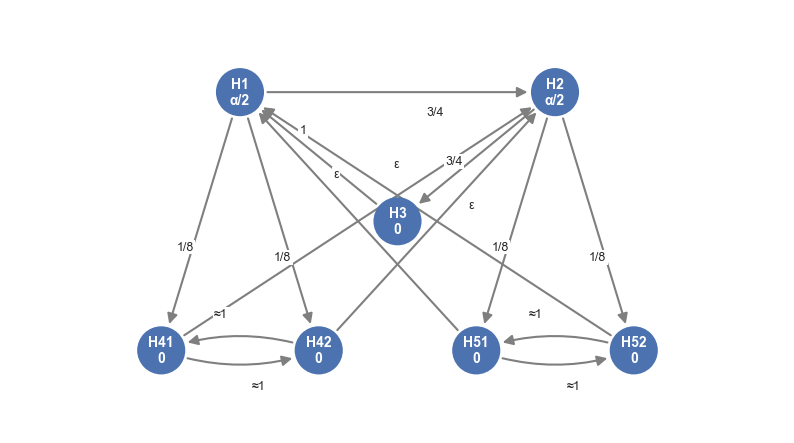

Обычный FWER:               H2, H52, H51
Дополненная, k = 2, δ = 0.5: H2, H52, H51, H3
Дополненная, γ = 0.3, δ = 0.5: H2, H52, H51, H3
Обобщённая, k = 2:          H2
Обобщённая, γ = 0.3:        H2


In [19]:
epsilon = 1e-8
atm_labels = ['H1', 'H2', 'H3', 'H41', 'H42', 'H51', 'H52']
atm_weights = np.array([0.5, 0.5, 0, 0, 0, 0, 0])
atm_p = np.array([0.1, 0.007, 0.05, 0.0015, 0.04, 0.0031, 0.001])

atm_G = np.zeros((7, 7))
atm_G[0, 1], atm_G[0, 3], atm_G[0, 4] = 3 / 4, 1 / 8, 1 / 8
atm_G[1, 2], atm_G[1, 5], atm_G[1, 6] = 3 / 4, 1 / 8, 1 / 8
atm_G[2, 0] = 1
atm_G[3, 4] = atm_G[4, 3] = atm_G[5, 6] = atm_G[6, 5] = 1 - epsilon
atm_G[3, 1] = atm_G[4, 1] = atm_G[5, 0] = atm_G[6, 0] = epsilon

atm_pos = [[0, 2], [4, 2], [2, 1], [-1, 0], [1, 0], [3, 0], [5, 0]]
fig, ax = plt.subplots(figsize=(10, 5.5))
draw_graph(ax, atm_weights, atm_G, atm_labels, pos=atm_pos, node_size=1200, font_size=10)
plt.show()

show = lambda rejected: ', '.join(atm_labels[i] for i in rejected)
print('Обычный FWER:              ', show(graph_test(atm_weights, atm_G, atm_p, 0.025)))
print('Дополненная, k = 2, δ = 0.5:', show(augmented_test(atm_weights, atm_G, atm_p, 0.025, k=2, delta=0.5)))
print('Дополненная, γ = 0.3, δ = 0.5:', show(augmented_test(atm_weights, atm_G, atm_p, 0.025, gamma=0.3, delta=0.5)))
print('Обобщённая, k = 2:         ', show(generalised_kfwer(atm_weights, atm_G, atm_p, 0.025, 2)))
print('Обобщённая, γ = 0.3:       ', show(generalised_fdp(atm_weights, atm_G, atm_p, 0.025, 0.3)))

**Результаты**

Обычная FWER-процедура отвергает $H_2$, $H_{51}$ и $H_{52}$. После этого на оставшемся графе ненулевые веса имеют только $H_1$ ($5/8$) и $H_3$ ($3/8$).

* **k-FWER, $k=2$.** Дополненная процедура с $\delta = 0.5$ продолжает на этом графе. Пороги равны $5\delta/8 = 0.3125$ для $H_1$ и $3\delta/8 = 0.1875$ для $H_3$. Отношение $p/w$ меньше у $H_3$ ($0.05 / 0.375 = 0.13$), и она отвергается.
* **FDP, $\gamma = 0.3$.** При $|R| = 3$ получаем $D = 1$ и то же дополнительное отвержение $H_3$.
* **Обобщённые процедуры.** При $k = 2$ отвергается только $H_2$, что меньше, чем у обычного FWER-теста. Обобщённая FDP-процедура сначала отвергает три гипотезы, но так как $3 > 1/\gamma - 1$, она переходит к $k = 2$ и тоже заканчивает только с $H_2$.

**Обсуждение и выводы**

Кейс ATMOSPHERE иллюстрирует несколько важных моментов:

1. **Иерархические графы с несколькими семействами** естественно возникают в подтверждающих испытаниях и легко реализуются графическим методом.
2. **Обычный FWER-тест** успешно перераспределяет уровни между семействами, позволяя тестировать вторичные конечные точки, если первичные значимы. В данном примере отвергнуты три гипотезы, включая обе вторичные для сравнения A и E.
3. **Дополненные процедуры** дают дополнительное отвержение: здесь это $H_3$.
4. **Обобщённые процедуры** в таких иерархических структурах часто дают даже меньше отверждений, чем обычный FWER, из-за проблемы доноров. Это делает их малопривлекательными для практического использования в сложных дизайнах.
5. **Практическая рекомендация:** в подтверждающих испытаниях со сложной иерархией (несколько первичных, несколько вторичных семейств) предпочтительно использовать либо классический графический FWER-тест, либо, если допустимо ослабление контроля, дополненную процедуру для k-FWER/FDP. Обобщённую процедуру следует применять с большой осторожностью, убедившись, что все гипотезы имеют достаточное число доноров.

### Симуляция для A/B-теста

Вернёмся к A/B-тестам. Два варианта сравниваются с контролем. Для каждого варианта есть основная метрика (revenue) и guardrail-метрика. Логика такая: guardrail проверяем, только если вариант доказал эффект по revenue. Освободившийся уровень возвращается на другой вариант.

Такой граф взят из Maurer et al. (2011): $H_1, H_2$ — первичные гипотезы вариантов, $H_3, H_4$ — их вторичные гипотезы.

Сравним граф с Бонферрони и Холмом на всех четырёх гипотезах. Статистики зависимы: варианты делят контроль, а метрики внутри варианта коррелируют. Считаем односторонние z-тесты с $\alpha = 0.05$. Сдвиг $z$ на 2.5 соответствует мощности примерно 80%.

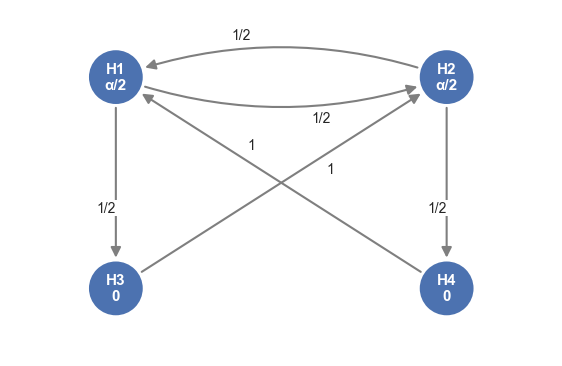

FWER  Мощность H1  Мощность H2  \
Сценарий                  Процедура                                     
Эффектов нет              Бонферрони  0.043        0.012        0.012   
                          Холм        0.043        0.013        0.012   
                          Граф        0.046        0.027        0.026   
Работает только вариант 1 Бонферрони  0.023        0.604        0.012   
                          Холм        0.042        0.629        0.025   
                          Граф        0.046        0.709        0.046   
Работают оба варианта     Бонферрони  0.000        0.604        0.604   
                          Холм        0.000        0.709        0.710   
                          Граф        0.000        0.757        0.758   

                                      Мощность H3  \
Сценарий                  Процедура                 
Эффектов нет              Бонферрони        0.013   
                          Холм              0.014   
                          Граф              0.002   
Работает только вариант 1 Бонферрони        0.605   
                          Холм              0.630   
                          Граф              0.488   
Работают оба варианта     Бонферрони        0.605   
                          Холм              0.707   
                          Граф              0.608   

                                      Guardrail без успеха варианта  
Сценарий                  Процедура                                  
Эффектов нет              Бонферрони                          0.022  
                          Холм                                0.022  
                          Граф                                0.000  
Работает только вариант 1 Бонферрони                          0.188  
                          Холм                                0.167  
                          Граф                                0.000  
Работают оба варианта     Бонферрони                          0.295  
                          Холм                                0.182  
                          Граф                                0.000

In [20]:
ab_weights = np.array([0.5, 0.5, 0, 0])
ab_G = np.array([[0, 1/2, 1/2, 0],
                 [1/2, 0, 0, 1/2],
                 [0, 1, 0, 0],
                 [1, 0, 0, 0]])
ab_correlation = np.array([[1.0, 0.5, 0.4, 0.2],
                           [0.5, 1.0, 0.2, 0.4],
                           [0.4, 0.2, 1.0, 0.5],
                           [0.2, 0.4, 0.5, 1.0]])

fig, ax = plt.subplots(figsize=(7, 4.5))
draw_graph(ax, ab_weights, ab_G, ['H1', 'H2', 'H3', 'H4'], pos=gate_pos)
plt.show()

from scipy.stats import norm

holm4_weights = np.full(4, 1 / 4)
holm4_G = (np.ones((4, 4)) - np.eye(4)) / 3
bonferroni4_G = np.zeros((4, 4))
procedures = {'Бонферрони': (holm4_weights, bonferroni4_G), 'Холм': (holm4_weights, holm4_G), 'Граф': (ab_weights, ab_G)}


def simulate_ab(effects: list, n_sims: int = 20_000, alpha: float = 0.05, seed: int = 42) -> pd.DataFrame:
    """Оценивает FWER, мощность и нарушения иерархии для процедур при заданных сдвигах z."""
    rng = np.random.default_rng(seed)
    effects = np.array(effects, dtype=float)
    z = rng.multivariate_normal(effects, ab_correlation, size=n_sims)
    pvalues = norm.sf(z)
    is_null = effects == 0

    rows = {}
    for name, (weights, G) in procedures.items():
        decisions = np.zeros((n_sims, 4), dtype=bool)
        for sim in range(n_sims):
            decisions[sim, graph_test(weights, G, pvalues[sim], alpha)] = True
        rows[name] = {
            'FWER': decisions[:, is_null].any(axis=1).mean() if is_null.any() else 0.0,
            'Мощность H1': decisions[:, 0].mean(),
            'Мощность H2': decisions[:, 1].mean(),
            'Мощность H3': decisions[:, 2].mean(),
            'Guardrail без успеха варианта': ((decisions[:, 2] & ~decisions[:, 0]) | (decisions[:, 3] & ~decisions[:, 1])).mean(),
        }
    return pd.DataFrame(rows).T


scenarios = {
    'Эффектов нет': [0, 0, 0, 0],
    'Работает только вариант 1': [2.5, 0, 2.5, 0],
    'Работают оба варианта': [2.5, 2.5, 2.5, 2.5],
}
ab_results = pd.concat({name: simulate_ab(effects) for name, effects in scenarios.items()}, names=['Сценарий', 'Процедура'])
ab_results.round(3)

Что показывает симуляция:

* **FWER** не превышает 5% у всех процедур во всех сценариях.
* **Мощность на основной метрике выше у графа.** Если работает один вариант, $H_1$ отвергается в 71% случаев против 63% у Холма и 60% у Бонферрони. Если работают оба, получаем 76%, 71% и 60%.
* **Цена — вторичные гипотезы.** Мощность $H_3$ падает до 49–61% против 63–71% у Холма, потому что guardrail проверяется только после успеха варианта по revenue.
* **Граф не даёт нелогичных исходов.** Плоские поправки при реальных эффектах в 17–30% случаев отвергают гипотезу о guardrail у варианта, который не доказал эффект по revenue. У графа это невозможно по построению.

Граф не бесплатен: он переносит мощность на приоритетные гипотезы и закрепляет логику решения заранее.

## Сравнительный анализ и практические рекомендации

Мы прошли большой путь — от простой поправки Бонферрони до обобщённых графических процедур, контролирующих k-FWER и FDP. Теперь пора подвести итоги и дать практические ориентиры: когда стоит применять графический подход, в чём его сильные стороны, где скрываются подводные камни и какие направления остаются открытыми.

### Когда выбирать графический подход

Графический подход является мощным, но не универсальным инструментом. Его применение оправдано, когда выполняются следующие условия:

1. **Иерархическая или логическая структура гипотез.**  
   Если ваши гипотезы естественно группируются в первичные и вторичные семейства, образуют цепочки «от более важных к менее важным» или подчиняются логике «K из N» — графический подход незаменим. Он позволяет закодировать эту структуру в топологии графа, что невозможно сделать с помощью плоских процедур вроде Холма или Бенджамини–Хохберг.

2. **Необходимость прозрачной коммуникации с нестатистиками.**  
   Граф можно нарисовать на доске и обсудить с клинической командой, продакт-менеджерами или регуляторами. Визуализация гораздо нагляднее, чем таблицы весов для сотен пересечений гипотез. Это особенно важно в клинических испытаниях, где дизайн должен быть одобрен регуляторными органами.

3. **Потребность в «рециклинге» уровня значимости.**  
   В сложных A/B-тестах мы не хотим «терять» уровень отвергнутой гипотезы — мы хотим передавать его другим, ещё не проверенным. Графический подход с рёбрами и весами делает этот рециклинг явным и автоматическим.

4. **Необходимость строгого контроля FWER (или k-FWER/FDP) при произвольной зависимости.**  
   Все процедуры, основанные на взвешенном Бонферрони, не требуют никаких предположений о структуре зависимости p-значений. Это даёт универсальную гарантию контроля ошибок.

Если же ваши гипотезы независимы (или слабо зависимы), и никакой иерархии нет, возможно, более простые методы (например, Бенджамини–Хохберга) дадут более высокую мощность при контроле FDR.

### Подводные камни и направления развития

#### Известные проблемы

1. **Проблема доноров в обобщённой процедуре.**  
   Если гипотеза имеет менее $k$ доноров, обобщённая процедура не может увеличить её вес после отвержения других гипотез. В иерархических графах это приводит к катастрофической потере мощности. Дополненная процедура не страдает от этого недостатка, поэтому авторы рекомендуют именно её.

2. **Вычислительная сложность обобщённых процедур при больших $m$ и $k>1$.**  
   Алгоритм обобщенных процедур требует перебора подмножеств размера $k-1$ из множества отвергнутых гипотез $R$. При $|R| \approx m$ и больших $k$ число комбинаций $\binom{|R|}{k-1}$ делает вычисления нереализуемыми. В статье предложены упрощённые варианты, но они дают лишь асимптотический контроль и всё равно требуют аккуратной реализации. Дополненные процедуры, напротив, имеют линейную сложность.

3. **Отсутствие скорректированных $p$-значений для дополненных процедур.**  
   В классическом графическом подходе можно вычислить adjusted p-value для каждой гипотезы — это позволяет легко применять тест при любом $\alpha$. Для дополненной процедуры аналогичный аппарат пока не разработан. Приходится запускать тест заново для каждого интересующего $\alpha$, что замедляет анализ чувствительности. Это открытая методологическая задача.

#### Направления развития

- **Интеграция с машинным обучением.** Автоматическое построение оптимального графа по историческим данным (например, оценка матрицы переходов, максимизирующей мощность при ограничениях на FWER).
- **Байесовские графические процедуры.** Адаптация идей graphical approach к задачам с априорными распределениями, где контролируется posterior probability ошибок.
- **Унификация с FDR-контролем.** Разработка графических процедур, контролирующих FDR в конечной выборке, а не только асимптотически.
- **Расширение на многомерные параметрические тесты.** Разработка устойчивых методов проверки монотонности для произвольных ковариационных матриц, чтобы можно было безопасно применять параметрический графический подход в любых A/B-тестах.
- **Онлайн-мониторинг и непрерывный анализ.**  
   В современных A/B-экспериментах всё чаще применяется непрерывный мониторинг (continuous monitoring) с ранней остановкой при достижении значимости. Графический подход в текущем виде ориентирован на фиксированное число проверок (или групповые последовательные дизайны с заранее заданными моментами анализа). Перенос графических процедур на полностью онлайн-режим (например, с использованием always-valid p-values) — актуальное направление исследований.

## Заключение

* Графический подход превращает стратегию проверки гипотез в наглядный граф: вершины получают доли уровня значимости, а рёбра задают, куда уровень перейдёт после отвержения.
* Уровень передаётся только при отвержении гипотезы. Неотвергнутая гипотеза свой уровень не отдаёт.
* Алгоритм — это сокращённая замкнутая процедура со взвешенными тестами Бонферрони, поэтому он контролирует FWER при любой зависимости тестов.
* Бонферрони, Холм, фиксированная последовательность и гейткипинг получаются как частные случаи графа.
* Для ослабленного контроля k-FWER и FDP в иерархиях лучше подходит дополненный подход, но дополнительные находки не стоит считать доказанными.
* В A/B-тестах граф полезен, когда нужно заранее закрепить приоритет метрик и логику проверки.